<div style="text-align: center; color:rgb(0, 0, 0); font-family: Arial, sans-serif; background-color:rgb(137, 200, 129); padding: 10px; border-radius: 10px; box-shadow: 0 4px 8px rgba(0, 0, 0, 1.2); line-height: 0.1;">

### **Series de Tiempo**
#### **Universidad Central**
#### Maestría en Analítica de Datos
#### Docente: Wilson Sandoval Rodriguez
##### wsandovalr@ucentral.edu.co

</div>

# 🔎 Introducción a los modelos de Vectores Autorregresivos — VAR($p$)

**Caso de estudio:** dinámica conjunta del crecimiento del PIB (GDP) y el desempleo (U) en Estados Unidos, 1948–1987 (datos de Blanchard y Quah, 1989).

Ruta de trabajo de cada técnica: **¿qué queremos saber? → hipótesis → código → resultado → decisión estadística → interpretación → precaución.**

## 0. Objetivos de aprendizaje

Al finalizar este cuaderno, el estudiante podrá:

1. Explicar qué problema resuelve un VAR y en qué se diferencia de un AR univariado, un SVAR y un VECM.
2. Escribir la especificación matemática de un VAR($p$) e interpretar cada uno de sus elementos.
3. Verificar las condiciones de uso (estacionariedad, frecuencia común, tamaño muestral, número de parámetros).
4. Seleccionar el orden $p$ con criterios de información y estimar el modelo con `statsmodels`.
5. Evaluar la **estabilidad** del sistema y el **diagnóstico de residuos**.
6. Aplicar e interpretar correctamente la **causalidad de Granger**.
7. Construir e interpretar **funciones impulso-respuesta (IRF)** y la **descomposición de varianza (FEVD)**, reconociendo su dependencia de la identificación.
8. Evaluar pronósticos fuera de muestra y generar pronósticos con intervalos de confianza.
9. Distinguir entre **resultado estadístico, interpretación y limitación**.

### Configuración del entorno

Todas las importaciones y opciones generales se concentran en esta celda. El cuaderno está diseñado para ejecutarse **de principio a fin, en orden**.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Math
from scipy import stats

from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tools.sm_exceptions import InterpolationWarning

pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

ALPHA = 0.05  # nivel de significancia usado en todas las pruebas
NOMBRES = {"GDP": "Crecimiento del PIB real (GDP)", "U": "Desempleo sin tendencia (U)"}
COLORES = {"GDP": "#1f77b4", "U": "#d62728"}


def formato_p(p):
    """p-valor legible: evita mostrar 0.0000 cuando es muy pequeño."""
    return "< 0.0001" if p < 1e-4 else f"{p:.4f}"


def decidir(p, alpha=ALPHA):
    return "Se rechaza H0" if p < alpha else "No se rechaza H0"

## 1. ¿Por qué necesitamos modelos VAR?

Piense en el PIB y el desempleo: cuando la economía crece, las empresas contratan y el desempleo tiende a bajar; cuando el desempleo es alto, el consumo se debilita y el crecimiento se resiente. **Cada variable ayuda a explicar la evolución futura de la otra.**

- Un **ARIMA univariado** del PIB ignora la información contenida en el desempleo, y viceversa.
- Una **regresión** del PIB sobre el desempleo obliga a decidir *a priori* cuál variable es exógena; si ambas se determinan conjuntamente, esa decisión es arbitraria.
- Un **VAR** trata a todas las variables como **endógenas** y de forma **simétrica**: cada variable se explica por sus propios rezagos y por los rezagos de las demás.

Christopher Sims (1980) propuso el VAR como alternativa a los grandes modelos macroeconométricos, cuyas restricciones de identificación consideraba "increíbles". El VAR deja que los datos describan la dinámica conjunta con un mínimo de supuestos teóricos.

**Precisión importante.** El VAR en forma reducida *no resuelve* la simultaneidad: como en el lado derecho solo aparecen valores rezagados, cada ecuación puede estimarse consistentemente por MCO, pero las relaciones **contemporáneas** entre variables quedan escondidas en la correlación de los errores. Darles una interpretación causal requiere supuestos adicionales de **identificación** (VAR estructural).

**Usos habituales de un VAR estimado**

| Pregunta | Herramienta |
|---|---|
| ¿Cómo será el futuro de las variables? | Pronóstico |
| ¿El pasado de $X$ ayuda a predecir $Y$? | Causalidad de Granger |
| ¿Cómo se propaga en el tiempo una perturbación? | Funciones impulso-respuesta (IRF) |
| ¿Qué innovaciones explican la incertidumbre del pronóstico? | Descomposición de varianza (FEVD) |

Construir el modelo sigue el ciclo iterativo de Box y Jenkins: **especificación → estimación → diagnóstico → uso** (y volver a especificar si el diagnóstico falla).

## 2. Del AR al VAR

Un **AR($p$) univariado** describe una sola serie con su propio pasado:

$$
y_t = c + \phi_1 y_{t-1} + \cdots + \phi_p y_{t-p} + \varepsilon_t .
$$

El **VAR($p$)** generaliza la idea: $y_t$ pasa a ser un **vector** de $k$ series, los coeficientes $\phi_i$ pasan a ser **matrices** $k\times k$ y el error pasa a ser un **vector** de innovaciones con matriz de covarianza $\Sigma$.

| Modelo | ¿Qué describe? | ¿Cuándo aparece? |
|---|---|---|
| **AR / ARIMA** | Una serie en función de su propio pasado | Interés en una sola variable; las demás no aportan información predictiva |
| **VAR (forma reducida)** | Varias series estacionarias en función del pasado de todas | Pronóstico conjunto, Granger, dinámica descriptiva |
| **SVAR (VAR estructural)** | Un VAR con restricciones que identifican *shocks* económicamente interpretables | Cuando se quiere hablar de "shocks de oferta", "shocks de política", etc. Ejemplo: Blanchard y Quah (1989) identifican shocks de oferta y demanda con **estos mismos datos** mediante restricciones de largo plazo |
| **VECM** | Un VAR para series $I(1)$ **cointegradas**, que combina dinámica de corto plazo y equilibrio de largo plazo | Las series tienen raíz unitaria pero existe una combinación lineal estacionaria entre ellas |

En este cuaderno trabajamos únicamente el **VAR en forma reducida**; SVAR y VECM se estudian en sesiones posteriores.

## 3. Formulación matemática

### 3.1 VAR($p$) general

$$
\mathbf{y}_t = \mathbf{c} + A_1\mathbf{y}_{t-1} + A_2\mathbf{y}_{t-2} + \cdots + A_p\mathbf{y}_{t-p} + \boldsymbol{\varepsilon}_t ,
\qquad t = p+1,\dots,T
$$

| Símbolo | Dimensión | Significado |
|---|---|---|
| $k$ | escalar | Número de variables del sistema (aquí $k=2$: GDP y U) |
| $p$ | escalar | Número de rezagos (orden del VAR); se exige $A_p \neq \mathbf{0}$ |
| $\mathbf{y}_t$ | $k\times 1$ | Vector de variables en el periodo $t$ |
| $\mathbf{c}$ | $k\times 1$ | Vector de interceptos |
| $A_i$ | $k\times k$ | Matriz de coeficientes del rezago $i$; el elemento $a_{ij,\ell}$ mide cómo el rezago $\ell$ de la variable $j$ entra en la ecuación de la variable $i$ |
| $\boldsymbol{\varepsilon}_t$ | $k\times 1$ | Vector de **innovaciones** (errores de pronóstico a un paso) |

Supuestos sobre las innovaciones (ruido blanco vectorial):

$$
E(\boldsymbol{\varepsilon}_t)=\mathbf{0}, \qquad
E(\boldsymbol{\varepsilon}_t\boldsymbol{\varepsilon}_t')=\Sigma \ \ (\text{definida positiva}), \qquad
E(\boldsymbol{\varepsilon}_t\boldsymbol{\varepsilon}_s')=\mathbf{0}\ \ \text{para } t\neq s .
$$

Observe que $\Sigma$ **no tiene por qué ser diagonal**: las innovaciones de distintas variables pueden estar correlacionadas en el mismo periodo. Esa correlación contemporánea es la que más adelante obligará a "identificar" los shocks.

### 3.2 Caso bivariado VAR(1)

Con $\mathbf{y}_t = (GDP_t,\ U_t)'$:

$$
\begin{pmatrix} GDP_t \\ U_t \end{pmatrix}
=
\begin{pmatrix} c_1 \\ c_2 \end{pmatrix}
+
\begin{pmatrix} a_{11} & a_{12} \\ a_{21} & a_{22} \end{pmatrix}
\begin{pmatrix} GDP_{t-1} \\ U_{t-1} \end{pmatrix}
+
\begin{pmatrix} \varepsilon_{GDP,t} \\ \varepsilon_{U,t} \end{pmatrix},
\qquad
\Sigma=\begin{pmatrix} \sigma_{GDP}^2 & \sigma_{GDP,U} \\ \sigma_{GDP,U} & \sigma_{U}^2 \end{pmatrix}
$$

Escrito ecuación por ecuación:

$$
\begin{aligned}
GDP_t &= c_1 + a_{11}\,GDP_{t-1} + a_{12}\,U_{t-1} + \varepsilon_{GDP,t}\\
U_t   &= c_2 + a_{21}\,GDP_{t-1} + a_{22}\,U_{t-1} + \varepsilon_{U,t}
\end{aligned}
$$

| Coeficiente | Interpretación |
|---|---|
| $a_{11}$ | Persistencia del crecimiento: relación entre $GDP_{t-1}$ y $GDP_t$, dado $U_{t-1}$ |
| $a_{12}$ | Relación entre el desempleo del trimestre anterior y el crecimiento actual, dado $GDP_{t-1}$ |
| $a_{21}$ | Relación entre el crecimiento del trimestre anterior y el desempleo actual, dado $U_{t-1}$ (ley de Okun en versión dinámica) |
| $a_{22}$ | Persistencia del desempleo |
| $\sigma_{GDP,U}$ | Covarianza **contemporánea** de las innovaciones: noticias que afectan a ambas variables en el mismo trimestre |

Si $a_{12}=0$ el pasado del desempleo no ayuda a predecir el PIB: es exactamente lo que evalúa la **causalidad de Granger** (sección 13). Un VAR($p$) con $p>1$ simplemente agrega más matrices $A_2, \dots, A_p$.

### 💡 Piense antes de ejecutar

> Si $a_{12}=a_{21}=0$ y además $\Sigma$ es diagonal, ¿qué queda del VAR? ¿Ganaríamos algo modelando conjuntamente las dos series?

## 4. Supuestos y condiciones: ¿cuándo puedo utilizar un VAR?

| Condición | ¿Por qué importa? | ¿Qué hacer si no se cumple? |
|---|---|---|
| **Estacionariedad** | Con raíces unitarias la inferencia usual (t, F) deja de ser válida y aparecen regresiones espurias | Diferenciar; si hay cointegración, usar un VECM |
| **Relación temporal entre las variables** | Si las variables no se influyen dinámicamente, el VAR solo agrega parámetros | Justificar el sistema con teoría o evidencia previa |
| **Frecuencia común** | Todas las ecuaciones comparten los mismos rezagos | Agregar o desagregar a una frecuencia común (p. ej., trimestral) |
| **Sin valores faltantes** | Cada rezago necesita observaciones completas de todas las variables | Imputar con cuidado o recortar la muestra |
| **Tamaño de muestra suficiente** | Cada ecuación estima $1+kp$ coeficientes con $T-p$ observaciones | Reducir $k$ o $p$, o usar VAR bayesianos o penalizados |

### El problema de la dimensionalidad

- Cada ecuación tiene $1 + kp$ coeficientes.
- El sistema completo tiene $k(1+kp)$ coeficientes **más** $k(k+1)/2$ elementos distintos de $\Sigma$.

El número de parámetros crece **cuadráticamente** con $k$ y linealmente con $p$. Agregar variables o rezagos "por si acaso" consume grados de libertad, infla la varianza de los estimadores y empeora el pronóstico (sobreajuste).

In [2]:
# Parámetros de un VAR(p) con k variables y razón observaciones/parámetro por ecuación
T_REFERENCIA = 160  # aproximadamente 40 años de datos trimestrales, como en este ejemplo
filas = []
for k in (2, 3, 5, 8):
    for p in (1, 2, 4, 8):
        por_ecuacion = 1 + k * p
        filas.append({
            "k": k, "p": p,
            "Total de parámetros": k * por_ecuacion + k * (k + 1) // 2,
            "Obs. por parámetro (ecuación)": (T_REFERENCIA - p) / por_ecuacion,
        })
parametros = pd.DataFrame(filas)

print("Total de parámetros (coeficientes + covarianzas):")
display(parametros.pivot(index="k", columns="p", values="Total de parámetros"))
print(f"Observaciones disponibles por parámetro en cada ecuación (T = {T_REFERENCIA}):")
display(parametros.pivot(index="k", columns="p", values="Obs. por parámetro (ecuación)").round(1))

Total de parámetros (coeficientes + covarianzas):


p,1,2,4,8
k,,,,
2,9,13,21,37
3,18,27,45,81
5,45,70,120,220
8,108,172,300,556


Observaciones disponibles por parámetro en cada ecuación (T = 160):


p,1,2,4,8
k,,,,
2,53.0,31.6,17.3,8.9
3,39.8,22.6,12.0,6.1
5,26.5,14.4,7.4,3.7
8,17.7,9.3,4.7,2.3


### ⚠️ Cuidado con esta conclusión

> Un VAR con 8 variables y 8 rezagos estima 584 parámetros, y cada ecuación dispone de apenas unas 2 observaciones por coeficiente con 40 años de datos trimestrales. Que el *software* entregue resultados no significa que sean confiables.

## 5. Conjunto de datos

Usamos la base clásica de **Blanchard y Quah (1989)**, *"The Dynamic Effects of Aggregate Demand and Supply Disturbances"*, para EE. UU., con frecuencia **trimestral**:

| Variable | Descripción (según la construcción de Blanchard y Quah) |
|---|---|
| `GDP` | Tasa de crecimiento trimestral del producto real, expresada como desviación respecto a su media (los autores permiten un cambio de media en 1973–1974) |
| `U` | Tasa de desempleo expresada como desviación respecto a una tendencia lineal |

Las dos series vienen **ya transformadas** por los autores (crecimiento y desviación de tendencia). Esto es conocimiento del proceso generador de los datos y anticipa que las series deberían ser estacionarias, algo que verificaremos en la sección 7.

La columna `dates` codifica año y trimestre (`1948.02` = segundo trimestre de 1948). La usamos para construir un índice trimestral con fin de periodo (`QE`) y comprobamos que coincide con la columna original.

In [3]:
URL_DATOS = "https://raw.githubusercontent.com/Wilsonsr/Series-de-Tiempo/main/03_datos/14_var/blanchard_quah.csv"
RUTA_LOCAL = Path("../03_datos/14_var/blanchard_quah.csv")  # copia local del repositorio, si existe

crudo = pd.read_csv(RUTA_LOCAL if RUTA_LOCAL.exists() else URL_DATOS)

anio = crudo["dates"].astype(int)
trimestre = ((crudo["dates"] - anio) * 100).round().astype(int)
indice = pd.date_range(start=pd.Timestamp(anio[0], 3 * trimestre[0], 1), periods=len(crudo), freq="QE", name="fecha")
assert (indice.year == anio).all() and (indice.quarter == trimestre).all(), "El índice no coincide con la columna 'dates'"

datos = crudo[["GDP", "U"]].set_axis(indice)

print(f"Periodo: {indice[0].to_period('Q')} a {indice[-1].to_period('Q')} | T = {len(datos)} | frecuencia: {datos.index.freqstr}")
display(pd.DataFrame({
    "Observaciones": datos.count(),
    "Faltantes": datos.isna().sum(),
    "Media": datos.mean(),
    "Desv. estándar": datos.std(),
    "Mínimo": datos.min(),
    "Máximo": datos.max(),
}).round(3))

Periodo: 1948Q2 a 1987Q4 | T = 159 | frecuencia: QE-DEC


,Observaciones,Faltantes,Media,Desv. estándar,Mínimo,Máximo
GDP,159,0,0.0,1.105,-3.016,3.083
U,159,0,-0.0,1.317,-2.378,3.584


### 🔎 ¿Qué observa?

- No hay valores faltantes y el índice tiene frecuencia trimestral explícita, lo que evita advertencias de `statsmodels` sobre frecuencia no definida.
- Ambas medias son prácticamente cero, lo que concuerda con que las series están expresadas como **desviaciones** (de la media y de la tendencia, respectivamente).

## 6. Análisis exploratorio

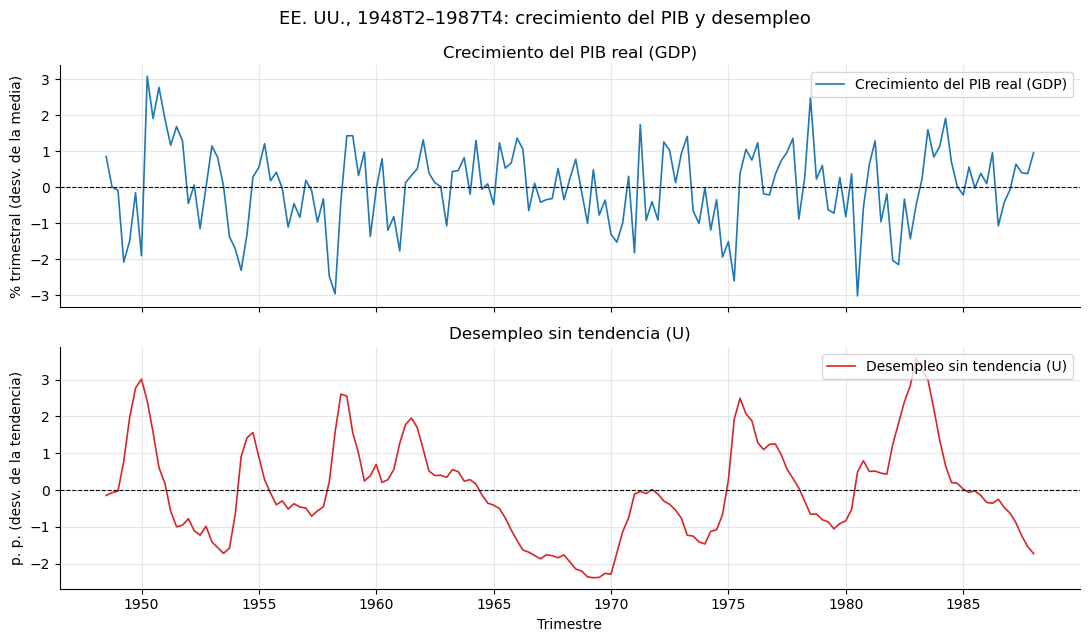

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
etiquetas_y = {"GDP": "% trimestral (desv. de la media)", "U": "p. p. (desv. de la tendencia)"}
for ax, var in zip(axes, datos.columns):
    ax.plot(datos.index, datos[var], color=COLORES[var], lw=1.2, label=NOMBRES[var])
    ax.axhline(0, color="black", lw=0.8, ls="--")
    ax.set_title(NOMBRES[var])
    ax.set_ylabel(etiquetas_y[var])
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Trimestre")
fig.suptitle("EE. UU., 1948T2–1987T4: crecimiento del PIB y desempleo", fontsize=13)
fig.tight_layout()
plt.show()

Para explorar la **relación dinámica** calculamos la correlación cruzada $\operatorname{corr}(GDP_{t-h},\,U_t)$. Un valor negativo en $h>0$ indica que un crecimiento alto **precede** a un desempleo bajo $h$ trimestres después.

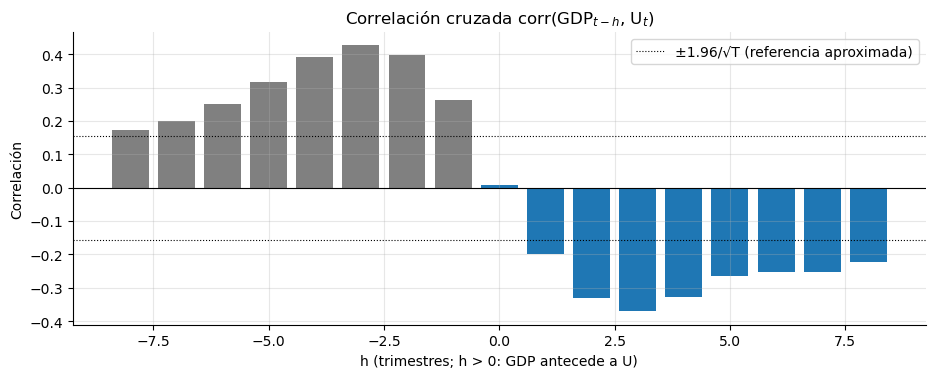

Correlación contemporánea (h = 0): 0.009
Correlación más negativa: -0.371 en h = 3


In [5]:
rezagos_cc = range(-8, 9)
correlacion_cruzada = pd.Series(
    [datos["U"].corr(datos["GDP"].shift(h)) for h in rezagos_cc], index=rezagos_cc
)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(correlacion_cruzada.index, correlacion_cruzada.values,
       color=np.where(correlacion_cruzada.index >= 0, COLORES["GDP"], "gray"))
banda = 1.96 / np.sqrt(len(datos))
ax.axhline(banda, color="black", ls=":", lw=0.8)
ax.axhline(-banda, color="black", ls=":", lw=0.8, label="±1.96/√T (referencia aproximada)")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Correlación cruzada corr(GDP$_{t-h}$, U$_t$)",
       xlabel="h (trimestres; h > 0: GDP antecede a U)", ylabel="Correlación")
ax.legend()
plt.show()

h_min = correlacion_cruzada.idxmin()
print(f"Correlación contemporánea (h = 0): {correlacion_cruzada[0]:.3f}")
print(f"Correlación más negativa: {correlacion_cruzada[h_min]:.3f} en h = {h_min}")

### 🔎 ¿Qué observa?

- Ambas series fluctúan alrededor de cero sin tendencia visible. El desempleo es mucho más **suave y persistente**, mientras que el crecimiento del PIB es más **ruidoso**.
- La correlación **contemporánea** entre las series es prácticamente nula, pero la correlación cruzada es negativa y más intensa cuando el PIB **antecede** al desempleo en unos pocos trimestres: los periodos de bajo crecimiento tienden a ser **seguidos** de desempleo por encima de su tendencia.
- La relación es, por tanto, esencialmente **dinámica** (con rezagos), justo el tipo de relación que un VAR está diseñado para capturar.

### ⚠️ Cuidado con esta conclusión

> Una correlación cruzada es una medida bivariada y no condicional: no controla el pasado del propio desempleo. El VAR sí lo hace.

## 7. Estacionariedad

### ¿Qué queremos saber?
Si cada serie tiene media y estructura de autocovarianzas estables en el tiempo, condición necesaria para estimar el VAR en niveles con inferencia estándar.

### Hipótesis — prueba de Dickey-Fuller aumentada (ADF)

$$
H_0:\ \text{la serie presenta raíz unitaria (no estacionaria)}
\qquad\text{vs.}\qquad
H_1:\ \text{la serie es estacionaria}
$$

**Regla de decisión** (con $\alpha = 0.05$):

- p-valor $< 0.05$ → **se rechaza $H_0$**: hay evidencia de estacionariedad.
- p-valor $\geq 0.05$ → **no existe evidencia suficiente para rechazar $H_0$**. Esto *no* demuestra que exista raíz unitaria: el ADF tiene baja potencia en muestras pequeñas.

Como las series fluctúan alrededor de cero sin tendencia, la especificación principal incluye **solo intercepto** (`regression="c"`). El número de rezagos aumentados se elige con BIC.

In [6]:
resultados_adf = {}
for var in datos.columns:
    estadistico, p_valor, rezagos, _, criticos, _ = adfuller(datos[var], regression="c", autolag="BIC")
    resultados_adf[var] = {
        "Estadístico ADF": round(estadistico, 3),
        "Valor crítico 5 %": round(criticos["5%"], 3),
        "Rezagos (BIC)": rezagos,
        "p-valor": formato_p(p_valor),
        "Decisión": decidir(p_valor),
        "Conclusión": (
            "Se rechaza la raíz unitaria: evidencia de estacionariedad"
            if p_valor < ALPHA else
            "No hay evidencia suficiente para rechazar la raíz unitaria"
        ),
        "_p": p_valor,
    }

tabla_adf = pd.DataFrame(resultados_adf).T
tabla_adf.index = [NOMBRES[v] for v in tabla_adf.index]
tabla_adf.index.name = "Variable"
display(tabla_adf.drop(columns="_p"))

,Estadístico ADF,Valor crítico 5 %,Rezagos (BIC),p-valor,Decisión,Conclusión
Variable,,,,,,
Crecimiento del PIB real (GDP),-8.523,-2.88,0,< 0.0001,Se rechaza H0,Se rechaza la raíz unitaria: evidencia de estacionariedad
Desempleo sin tendencia (U),-4.769,-2.88,1,< 0.0001,Se rechaza H0,Se rechaza la raíz unitaria: evidencia de estacionariedad


### Complementos al ADF

El ADF es **una** herramienta. Conviene contrastarla con:

1. **Análisis gráfico** (sección 6).
2. **Especificación con tendencia** (`regression="ct"`): verifica que la conclusión no dependa de omitir una tendencia determinística.
3. **Prueba KPSS**, que invierte las hipótesis: $H_0$: la serie es estacionaria; $H_1$: tiene raíz unitaria. Si el ADF rechaza y el KPSS no rechaza, ambas pruebas apuntan en la misma dirección.
4. **Conocimiento del proceso generador:** aquí las series ya son una tasa de crecimiento y una desviación de tendencia.

In [7]:
filas = []
for var in datos.columns:
    p_adf_c = resultados_adf[var]["_p"]
    p_adf_ct = adfuller(datos[var], regression="ct", autolag="BIC")[1]
    with warnings.catch_warnings():
        # KPSS solo tabula p-valores entre 0.01 y 0.10; fuera de ese rango avisa que truncó
        warnings.simplefilter("ignore", InterpolationWarning)
        p_kpss = kpss(datos[var], regression="c", nlags="auto")[1]

    p_kpss_txt = "≥ 0.10" if p_kpss >= 0.10 else ("≤ 0.01" if p_kpss <= 0.01 else f"{p_kpss:.4f}")
    coinciden = p_adf_c < ALPHA and p_adf_ct < ALPHA and p_kpss >= ALPHA
    filas.append({
        "Variable": NOMBRES[var],
        "ADF intercepto (p)": formato_p(p_adf_c),
        "ADF intercepto + tendencia (p)": formato_p(p_adf_ct),
        "KPSS, H0: estacionaria (p)": p_kpss_txt,
        "Conclusión conjunta": "Las tres pruebas son consistentes con estacionariedad" if coinciden
                               else "Resultados en conflicto: revisar especificación o transformación",
        "_ok": coinciden,
    })

robustez = pd.DataFrame(filas).set_index("Variable")
display(robustez.drop(columns="_ok"))

series_estacionarias = bool(robustez["_ok"].all())
print("Decisión de modelado:",
      "se estima el VAR con las series tal como están, sin transformaciones adicionales."
      if series_estacionarias else
      "revisar transformaciones (diferenciación) o considerar un VECM antes de estimar el VAR.")

,ADF intercepto (p),ADF intercepto + tendencia (p),"KPSS, H0: estacionaria (p)",Conclusión conjunta
Variable,,,,
Crecimiento del PIB real (GDP),< 0.0001,< 0.0001,≥ 0.10,Las tres pruebas son consistentes con estacionariedad
Desempleo sin tendencia (U),< 0.0001,0.0006,≥ 0.10,Las tres pruebas son consistentes con estacionariedad


Decisión de modelado: se estima el VAR con las series tal como están, sin transformaciones adicionales.


### 🧠 Interprete el resultado

- **Resultado:** la tabla muestra, para cada serie, si el ADF rechaza la raíz unitaria y si el KPSS rechaza la estacionariedad.
- **Interpretación:** si el ADF (con y sin tendencia) rechaza $H_0$ y el KPSS no la rechaza, la evidencia apunta a que la serie es estacionaria y **no es necesario diferenciarla**. Diferenciar una serie estacionaria introduciría una raíz unitaria en la parte de media móvil (sobrediferenciación) y eliminaría información.
- **Precaución:** el p-valor del KPSS se reporta truncado ("≥ 0.10") porque la tabla de la prueba no va más allá de ese valor.

## 8. Selección del orden $p$

### ¿Qué queremos saber?
¿Cuántos rezagos necesita el sistema? Pocos rezagos dejan dinámica sin capturar (residuos autocorrelacionados); demasiados desperdician grados de libertad.

### Criterios de información

Todos combinan **ajuste**, medido con $\ln|\hat\Sigma_\ell|$ (determinante de la matriz de covarianza residual con $\ell$ rezagos), y una **penalización** por el número de coeficientes $\ell k^2$:

$$
\begin{aligned}
\operatorname{AIC}(\ell)  &= \ln|\hat{\Sigma}_{\ell}| + \frac{2}{T}\,\ell k^{2}\\
\operatorname{BIC}(\ell)  &= \ln|\hat{\Sigma}_{\ell}| + \frac{\ln T}{T}\,\ell k^{2}\\
\operatorname{HQIC}(\ell) &= \ln|\hat{\Sigma}_{\ell}| + \frac{2\ln(\ln T)}{T}\,\ell k^{2}\\
\operatorname{FPE}(\ell)  &= \left(\frac{T+k\ell+1}{T-k\ell-1}\right)^{k}|\hat{\Sigma}_{\ell}|
\end{aligned}
$$

| Criterio | Idea | Tendencia |
|---|---|---|
| **AIC** (Akaike) | Minimiza la pérdida esperada de información | Penaliza poco; tiende a elegir modelos más grandes; buen desempeño predictivo |
| **BIC** (Schwarz) | Aproxima la probabilidad posterior del modelo | Penaliza más ($\ln T > 2$ si $T>7$); elige modelos parsimoniosos; consistente |
| **HQIC** (Hannan-Quinn) | Penalización intermedia | Consistente; suele quedar entre AIC y BIC |
| **FPE** (error final de predicción) | Estima el error cuadrático medio de pronóstico a un paso | Se comporta de forma similar al AIC |

**Regla:** para cada criterio, el valor **menor** indica el orden preferido. Para que los criterios sean comparables, `select_order` usa la **misma muestra** (las últimas $T - \text{maxlags}$ observaciones) en todos los órdenes. Con `maxlags=12` exploramos hasta tres años de rezagos trimestrales. También existen pruebas de razón de verosimilitud secuenciales, que no usamos aquí.

### 💡 Piense antes de ejecutar

> Si AIC y BIC no coinciden, ¿cuál esperaría que eligiera más rezagos? ¿Por qué?

In [8]:
modelo_var = VAR(datos)
seleccion = modelo_var.select_order(maxlags=12)
print(seleccion.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       0.5868      0.6275       1.798      0.6034
1       -2.873      -2.751     0.05653      -2.823
2      -2.972*     -2.769*    0.05119*     -2.890*
3       -2.970      -2.686     0.05129      -2.855
4       -2.956      -2.590     0.05203      -2.807
5       -2.918      -2.470     0.05407      -2.736
6       -2.924      -2.395     0.05378      -2.709
7       -2.880      -2.270     0.05619      -2.632
8       -2.834      -2.142     0.05891      -2.553
9       -2.802      -2.029     0.06085      -2.488
10      -2.812      -1.957     0.06033      -2.465
11      -2.815      -1.879     0.06023      -2.435
12      -2.822      -1.804     0.05991      -2.408
--------------------------------------------------


In [9]:
def elegir_orden(seleccion):
    """Usa el orden si todos los criterios coinciden; si no, prioriza BIC por parsimonia."""
    ordenes = {criterio.upper(): int(p) for criterio, p in seleccion.selected_orders.items()}
    if len(set(ordenes.values())) == 1:
        p = next(iter(ordenes.values()))
        motivo = f"todos los criterios coinciden en p = {p}"
    else:
        p = ordenes["BIC"]
        motivo = f"los criterios difieren {ordenes}; se adopta BIC (más parsimonioso), p = {p}"
    return p, ordenes, motivo


p_opt, ordenes_seleccionados, motivo = elegir_orden(seleccion)
display(pd.Series(ordenes_seleccionados, name="Rezago seleccionado").to_frame())
print(f"Orden adoptado: VAR({p_opt}) — {motivo}.")

,Rezago seleccionado
AIC,2
BIC,2
HQIC,2
FPE,2


Orden adoptado: VAR(2) — todos los criterios coinciden en p = 2.


### 🧠 Interprete el resultado

En la tabla de `select_order` el asterisco marca el mínimo de cada criterio, y la celda anterior extrae esos mínimos programáticamente. En la ejecución actual los cuatro criterios coinciden en el **mismo orden**, que es el que adopta `p_opt` y el que se usa en el resto del cuaderno. Si los datos o `maxlags` cambiaran, `p_opt` se actualizaría automáticamente.

Observe también que las diferencias entre $p=2$ y $p=3$ son pequeñas en AIC: el criterio da una preferencia, no una certeza. El diagnóstico de residuos (sección 12) confirmará si el orden elegido es suficiente.

## 9. Estimación del VAR

Como todas las ecuaciones tienen **los mismos regresores** (constante y $p$ rezagos de todas las variables), estimar cada ecuación por **MCO** es equivalente a la estimación conjunta (SUR) y, bajo normalidad, a máxima verosimilitud.

**Cómo leer `summary()`:**

1. **Encabezado:** número de ecuaciones, observaciones efectivas ($T-p$, porque se pierden los primeros $p$ periodos), log-verosimilitud y criterios de información del modelo estimado.
2. **Un bloque por ecuación** (`Results for equation GDP`, `... U`): coeficiente, error estándar, estadístico $t$ y p-valor de cada regresor. `L1.U` significa "$U$ rezagado un periodo".
3. **Matriz de correlación de los residuos:** correlación contemporánea de las innovaciones $\hat\varepsilon_{GDP,t}$ y $\hat\varepsilon_{U,t}$.

In [10]:
modelo = modelo_var.fit(p_opt)
print(modelo.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 16, Oct, 2026
Time:                     23:35:11
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -2.65825
Nobs:                     157.000    HQIC:                  -2.77385
Log likelihood:          -211.593    FPE:                  0.0576785
AIC:                     -2.85291    Det(Omega_mle):       0.0541731
--------------------------------------------------------------------
Results for equation GDP
            coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------
const         -0.015705         0.076842           -0.204           0.838
L1.GDP         0.069048         0.107822            0.640           0.522
L1.U          -0.615301         0.307235           -2.003           0.045
L2.GDP         0

## 10. Interpretación del modelo

Para un VAR(2), que es el orden seleccionado en la ejecución actual, el sistema tiene dos ecuaciones:

$$
\begin{aligned}
GDP_t &= c_1 + \phi_{11}\,GDP_{t-1} + \phi_{12}\,U_{t-1} + \phi_{13}\,GDP_{t-2} + \phi_{14}\,U_{t-2} + \varepsilon_{GDP,t}\\
U_t   &= c_2 + \phi_{21}\,GDP_{t-1} + \phi_{22}\,U_{t-1} + \phi_{23}\,GDP_{t-2} + \phi_{24}\,U_{t-2} + \varepsilon_{U,t}
\end{aligned}
$$

**Cómo interpretar un coeficiente individual.** $\phi_{12}$ es el cambio esperado en $GDP_t$ asociado a un aumento de una unidad en $U_{t-1}$, **manteniendo constantes los demás rezagos** de la ecuación. Es un efecto **condicional y predictivo**, no causal:

- no dice qué pasaría si se *interviniera* el desempleo;
- los rezagos de una misma variable suelen estar correlacionados entre sí, por lo que sus coeficientes individuales pueden tener signos opuestos y errores estándar grandes;
- la pregunta "¿el desempleo ayuda a predecir el PIB?" se responde evaluando **conjuntamente** $\phi_{12}=\phi_{14}=0$ (causalidad de Granger, sección 13), no mirando cada $t$ por separado.

La celda siguiente construye las ecuaciones estimadas y una tabla de coeficientes cuya interpretación se genera a partir de los resultados.

In [11]:
def ecuacion_estimada(ecuacion):
    terminos = [f"{modelo.params.loc['const', ecuacion]:.3f}"]
    for regresor in modelo.params.index.drop("const"):
        rezago, variable = regresor.split(".")
        coef = modelo.params.loc[regresor, ecuacion]
        terminos.append(f"{'+' if coef >= 0 else '-'} {abs(coef):.3f}\\,{variable}_{{t-{rezago[1:]}}}")
    return rf"\widehat{{{ecuacion}}}_t &= " + " ".join(terminos)

display(Math(r"\begin{aligned}" + r"\\".join(ecuacion_estimada(e) for e in modelo.names) + r"\end{aligned}"))

filas = []
for ecuacion in modelo.names:
    for regresor in modelo.params.index:
        coef = modelo.params.loc[regresor, ecuacion]
        p_valor = modelo.pvalues.loc[regresor, ecuacion]
        if regresor == "const":
            texto = "Intercepto de la ecuación"
        else:
            rezago, variable = regresor.split(".")
            termino = f"{variable}(t-{rezago[1:]})"
            texto = (f"Dados los demás rezagos, +1 unidad en {termino} se asocia con {coef:+.3f} en {ecuacion}(t)"
                     if p_valor < ALPHA else
                     f"Sin evidencia individual (5 %) de asociación condicional entre {termino} y {ecuacion}(t)")
        filas.append({"Ecuación": ecuacion, "Variable rezagada": regresor, "Coeficiente": round(coef, 4),
                      "p-valor": formato_p(p_valor), "Interpretación": texto})

display(pd.DataFrame(filas).set_index(["Ecuación", "Variable rezagada"]))

<IPython.core.display.Math object>

Coeficiente   p-valor  \
Ecuación Variable rezagada                          
GDP      const                  -0.0157    0.8381   
         L1.GDP                  0.0690    0.5219   
         L1.U                   -0.6153    0.0452   
         L2.GDP                  0.0474    0.6023   
         L2.U                    0.9019    0.0041   
U        const                  -0.0075    0.7698   
         L1.GDP                 -0.1192    0.0009   
         L1.U                    1.3335  < 0.0001   
         L2.GDP                 -0.0299    0.3249   
         L2.U                   -0.4170  < 0.0001   

                                                                                              Interpretación  
Ecuación Variable rezagada                                                                                    
GDP      const                                                                     Intercepto de la ecuación  
         L1.GDP             Sin evidencia individual (5 %) de asociación condicional entre GDP(t-1) y GDP(t)  
         L1.U                    Dados los demás rezagos, +1 unidad en U(t-1) se asocia con -0.615 en GDP(t)  
         L2.GDP             Sin evidencia individual (5 %) de asociación condicional entre GDP(t-2) y GDP(t)  
         L2.U                    Dados los demás rezagos, +1 unidad en U(t-2) se asocia con +0.902 en GDP(t)  
U        const                                                                     Intercepto de la ecuación  
         L1.GDP                  Dados los demás rezagos, +1 unidad en GDP(t-1) se asocia con -0.119 en U(t)  
         L1.U                      Dados los demás rezagos, +1 unidad en U(t-1) se asocia con +1.333 en U(t)  
         L2.GDP               Sin evidencia individual (5 %) de asociación condicional entre GDP(t-2) y U(t)  
         L2.U                      Dados los demás rezagos, +1 unidad en U(t-2) se asocia con -0.417 en U(t)

In [12]:
correlacion_residuos = pd.DataFrame(modelo.resid_corr, index=modelo.names, columns=modelo.names)
print("Correlación contemporánea de las innovaciones:")
display(correlacion_residuos.round(3))

for ecuacion, variable in [("GDP", "U"), ("U", "U")]:
    suma = sum(modelo.params.loc[f"L{l}.{variable}", ecuacion] for l in range(1, p_opt + 1))
    print(f"Suma de los coeficientes de {variable} en la ecuación de {ecuacion}: {suma:.3f}")

Correlación contemporánea de las innovaciones:


,GDP,U
GDP,1.000,-0.656
U,-0.656,1.000


Suma de los coeficientes de U en la ecuación de GDP: 0.287
Suma de los coeficientes de U en la ecuación de U: 0.917


### 🧠 Interprete el resultado

- **Ecuación de U:** el desempleo es muy **persistente**: sus coeficientes propios son grandes y significativos, con signos que generan una dinámica suave, y su suma es cercana a uno. El crecimiento del PIB del trimestre anterior (`L1.GDP`) tiene coeficiente **negativo y significativo**: un crecimiento mayor se asocia con menor desempleo en el trimestre siguiente, dado el pasado del desempleo. Es coherente con la ley de Okun.
- **Ecuación de GDP:** los rezagos propios del crecimiento no son significativos individualmente. Los rezagos del desempleo sí lo son, pero con **signos opuestos** (`L1.U` negativo, `L2.U` positivo). Esto ilustra por qué los coeficientes individuales de un VAR son difíciles de interpretar: la respuesta neta del sistema se estudia mejor con IRF.
- **Innovaciones:** la correlación contemporánea entre los residuos es fuertemente negativa. En un mismo trimestre, una "noticia" que eleva el crecimiento suele coincidir con una que reduce el desempleo.

### ⚠️ Cuidado con esta conclusión

> "`L1.U` es significativo en la ecuación del PIB, luego el desempleo **causa** el PIB" es una conclusión incorrecta. El coeficiente mide una asociación condicional en una regresión predictiva. Además, su significancia individual no reemplaza la prueba conjunta de Granger.

## 11. Estabilidad del VAR

### ¿Qué queremos saber?
Si el sistema es **estable**: ante un shock, las variables vuelven a su media en lugar de divergir.

> **Intuición:** en un VAR estable, el efecto de un shock se disipa con el tiempo en lugar de crecer indefinidamente.

Un VAR estable es estacionario, tiene media finita $\boldsymbol\mu = (I - A_1 - \cdots - A_p)^{-1}\mathbf c$ y admite IRF y FEVD bien definidas.

### Dos representaciones equivalentes (fuente frecuente de confusión)

**(a) Polinomio característico.** La estabilidad exige que las raíces $z$ de

$$
\det\left(I_k - A_1 z - A_2 z^2 - \cdots - A_p z^p\right) = 0
$$

estén **fuera** del círculo unitario: $|z| > 1$. **Esto es lo que reporta `modelo.roots` en `statsmodels`.**

**(b) Forma compañera (VAR(1) apilado).** Todo VAR($p$) puede escribirse como un VAR(1) de dimensión $kp$, $\boldsymbol\xi_t = F\boldsymbol\xi_{t-1} + \mathbf v_t$, con

$$
F = \begin{pmatrix}
A_1 & A_2 & \cdots & A_{p-1} & A_p\\
I_k & 0 & \cdots & 0 & 0\\
0 & I_k & \cdots & 0 & 0\\
\vdots & & \ddots & & \vdots\\
0 & 0 & \cdots & I_k & 0
\end{pmatrix}.
$$

La estabilidad exige que los **autovalores** $\lambda$ de $F$ estén **dentro** del círculo unitario: $|\lambda| < 1$. Esto es lo que imprime `modelo.is_stable(verbose=True)` ("Eigenvalues of VAR(1) rep").

**Relación:** $\lambda = 1/z$. Por eso ambas condiciones son la misma, y por eso **no** debe exigirse que las raíces de `modelo.roots` estén dentro del círculo unitario. Muchos programas, como EViews, grafican las *raíces inversas* ($\lambda$), que sí deben quedar dentro del círculo.

In [13]:
k, p = modelo.neqs, modelo.k_ar
raices = modelo.roots

tabla_raices = pd.DataFrame({
    "Raíz z (modelo.roots)": [f"{z.real:.4f} {z.imag:+.4f}i" for z in raices],
    "Módulo |z|": np.abs(raices),
    "Cumple estabilidad (|z| > 1)": np.abs(raices) > 1,
})
print("(a) Raíces del polinomio característico — deben tener módulo MAYOR que 1")
display(tabla_raices.round(4))

# Matriz compañera F (kp x kp)
F = np.zeros((k * p, k * p))
F[:k, :] = np.hstack(modelo.coefs)
F[k:, :-k] = np.eye(k * (p - 1))
autovalores = np.linalg.eigvals(F)

tabla_autovalores = pd.DataFrame({
    "Autovalor λ de F": [f"{l.real:.4f} {l.imag:+.4f}i" for l in autovalores],
    "Módulo |λ|": np.abs(autovalores),
    "1/|λ|": 1 / np.abs(autovalores),
    "Cumple estabilidad (|λ| < 1)": np.abs(autovalores) < 1,
})
print("(b) Autovalores de la forma compañera — deben tener módulo MENOR que 1")
display(tabla_autovalores.round(4))

assert np.allclose(np.sort(np.abs(raices)), np.sort(1 / np.abs(autovalores))), "Las representaciones no coinciden"
print("Verificación: |z| = 1/|λ| para todas las raíces ✔\n")

print("Salida de statsmodels:")
estable = modelo.is_stable(verbose=True)

(a) Raíces del polinomio característico — deben tener módulo MAYOR que 1


,Raíz z (modelo.roots),Módulo |z|,Cumple estabilidad (|z| > 1)
0,-9.7404 +1.5489i,9.8627,True
1,-9.7404 -1.5489i,9.8627,True
2,1.1465 +0.3409i,1.1961,True
3,1.1465 -0.3409i,1.1961,True


(b) Autovalores de la forma compañera — deben tener módulo MENOR que 1


,Autovalor λ de F,Módulo |λ|,1/|λ|,Cumple estabilidad (|λ| < 1)
0,0.8014 +0.2383i,0.8361,1.1961,True
1,0.8014 -0.2383i,0.8361,1.1961,True
2,-0.1001 +0.0159i,0.1014,9.8627,True
3,-0.1001 -0.0159i,0.1014,9.8627,True


Verificación: |z| = 1/|λ| para todas las raíces ✔

Salida de statsmodels:
Eigenvalues of VAR(1) rep
0.8360669078789427
0.8360669078789427
0.10139162706594397
0.10139162706594397


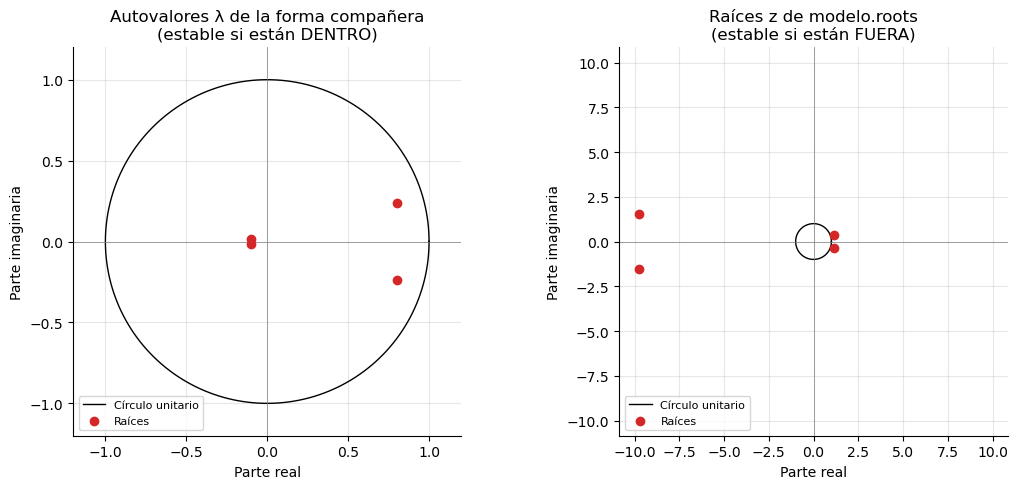

Conclusión: el VAR estimado es ESTABLE.
Módulo del autovalor dominante: 0.836. Un shock pierde la mitad de su efecto en aproximadamente 3.9 trimestres (aproximación basada en la raíz dominante).


In [14]:
rho = np.abs(autovalores).max()
vida_media = np.log(0.5) / np.log(rho)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
circulo = np.linspace(0, 2 * np.pi, 400)
for ax, valores, titulo, regla in [
    (axes[0], autovalores, "Autovalores λ de la forma compañera", "estable si están DENTRO"),
    (axes[1], raices, "Raíces z de modelo.roots", "estable si están FUERA"),
]:
    ax.plot(np.cos(circulo), np.sin(circulo), color="black", lw=1, label="Círculo unitario")
    ax.scatter(valores.real, valores.imag, color="C3", zorder=3, label="Raíces")
    limite = max(1.2, np.abs(valores).max() * 1.1)
    ax.set(xlim=(-limite, limite), ylim=(-limite, limite), aspect="equal",
           title=f"{titulo}\n({regla})", xlabel="Parte real", ylabel="Parte imaginaria")
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

print("Conclusión:", "el VAR estimado es ESTABLE." if estable else "el VAR estimado NO es estable: revisar especificación.")
print(f"Módulo del autovalor dominante: {rho:.3f}. Un shock pierde la mitad de su efecto en aproximadamente "
      f"{vida_media:.1f} trimestres (aproximación basada en la raíz dominante).")

### 🧠 Interprete el resultado

Todas las raíces de `modelo.roots` tienen módulo mayor que 1 o, de forma equivalente, todos los autovalores de la forma compañera están dentro del círculo unitario: el sistema es **estable**. El autovalor dominante, complejo y de módulo relativamente alto, indica que los shocks se disipan de forma **gradual y con algo de oscilación**, lo que veremos en las IRF.

### ⚠️ Cuidado con esta conclusión

> Un autovalor con módulo cercano a 1 (por ejemplo, 0.98) indica un sistema estable pero casi no estacionario. En ese caso las IRF decaen muy lentamente y los intervalos de confianza se vuelven muy amplios.

## 12. Diagnóstico de residuos

Si el VAR está bien especificado, las innovaciones deben comportarse como ruido blanco. Evaluamos tres aspectos.

### 12.1 Autocorrelación

**¿Qué queremos saber?** Si quedó dinámica sin capturar, por ejemplo por usar muy pocos rezagos.

**Prueba de Portmanteau multivariada** (`test_whiteness`), en la versión ajustada para muestras pequeñas:

$$
H_0:\ \text{no existe autocorrelación residual: } E(\boldsymbol\varepsilon_t\boldsymbol\varepsilon_{t-j}') = 0,\quad j=1,\dots,h
$$

Evalúa **simultáneamente** autocorrelaciones y correlaciones cruzadas de los residuos hasta el rezago $h$, con $k^2(h-p)$ grados de libertad (por eso se exige $h>p$). Como complemento pedagógico mostramos Ljung-Box **ecuación por ecuación**, que solo mira la autocorrelación de cada residuo con su propio pasado.

In [15]:
filas = []
for h in (4, 8, 12):
    prueba = modelo.test_whiteness(nlags=h, adjusted=True)
    filas.append({"h (rezagos)": h, "Estadístico": prueba.test_statistic, "gl": prueba.df,
                  "p-valor": formato_p(prueba.pvalue), "Decisión": decidir(prueba.pvalue)})
print("Portmanteau multivariado ajustado — H0: no hay autocorrelación residual hasta el rezago h")
display(pd.DataFrame(filas).set_index("h (rezagos)").round(3))

ljung_box = {var: acorr_ljungbox(modelo.resid[var], lags=[8]).iloc[0] for var in modelo.names}
print("Ljung-Box por ecuación (8 rezagos) — H0: no hay autocorrelación en el residuo de la ecuación")
display(pd.DataFrame({
    var: {"Estadístico Q": r["lb_stat"], "p-valor": formato_p(r["lb_pvalue"]), "Decisión": decidir(r["lb_pvalue"])}
    for var, r in ljung_box.items()
}).T)

Portmanteau multivariado ajustado — H0: no hay autocorrelación residual hasta el rezago h


,Estadístico,gl,p-valor,Decisión
h (rezagos),,,,
4,10.779,8,0.2146,No se rechaza H0
8,28.617,24,0.2349,No se rechaza H0
12,48.874,40,0.1586,No se rechaza H0


Ljung-Box por ecuación (8 rezagos) — H0: no hay autocorrelación en el residuo de la ecuación


,Estadístico Q,p-valor,Decisión
GDP,6.9586,0.5411,No se rechaza H0
U,14.2603,0.0752,No se rechaza H0


### 12.2 Normalidad

$$
H_0:\ \text{los residuos siguen una distribución normal}
$$

- **Jarque-Bera multivariado** (`test_normality`, Lütkepohl): evalúa asimetría y curtosis de los residuos **ortogonalizados** mediante Cholesky, por lo que depende del orden de las variables.
- **Jarque-Bera univariado** por ecuación, sobre los residuos sin transformar.

**¿Qué implica rechazar normalidad?** Los estimadores MCO de los coeficientes siguen siendo consistentes y la dinámica estimada (coeficientes, IRF puntuales) no queda invalidada. Sí se ven afectados los procedimientos que dependen de la normalidad en muestras finitas: intervalos de pronóstico, intervalos asintóticos de IRF y algunas pruebas. Una alternativa es usar intervalos por *bootstrap*.

In [16]:
normalidad_sistema = modelo.test_normality()
print(f"Jarque-Bera multivariado: estadístico = {normalidad_sistema.test_statistic:.3f}, "
      f"gl = {normalidad_sistema.df}, p-valor = {formato_p(normalidad_sistema.pvalue)} → {decidir(normalidad_sistema.pvalue)}")

# Residuos ortogonalizados (los que usa la prueba multivariada)
residuos_c = modelo.resid - modelo.resid.mean()
P = np.linalg.cholesky(residuos_c.cov(ddof=0).values)
residuos_ortogonales = pd.DataFrame(residuos_c.values @ np.linalg.inv(P).T, columns=modelo.names, index=modelo.resid.index)

jarque_bera = {var: stats.jarque_bera(modelo.resid[var]) for var in modelo.names}
display(pd.DataFrame({
    var: {
        "Asimetría": stats.skew(modelo.resid[var]),
        "Exceso de curtosis": stats.kurtosis(modelo.resid[var]),
        "JB univariado (p)": formato_p(jarque_bera[var].pvalue),
        "Decisión": decidir(jarque_bera[var].pvalue),
        "Asimetría (resid. ortogonalizado)": stats.skew(residuos_ortogonales[var]),
        "Exceso de curtosis (resid. ortogonalizado)": stats.kurtosis(residuos_ortogonales[var]),
    } for var in modelo.names
}).T)

Jarque-Bera multivariado: estadístico = 2.319, gl = 4, p-valor = 0.6772 → No se rechaza H0


,Asimetría,Exceso de curtosis,JB univariado (p),Decisión,Asimetría (resid. ortogonalizado),Exceso de curtosis (resid. ortogonalizado)
GDP,-0.1849,0.1761,0.5776,No se rechaza H0,-0.1849,0.1761
U,0.708,0.7165,0.0003,Se rechaza H0,0.216,-0.0113


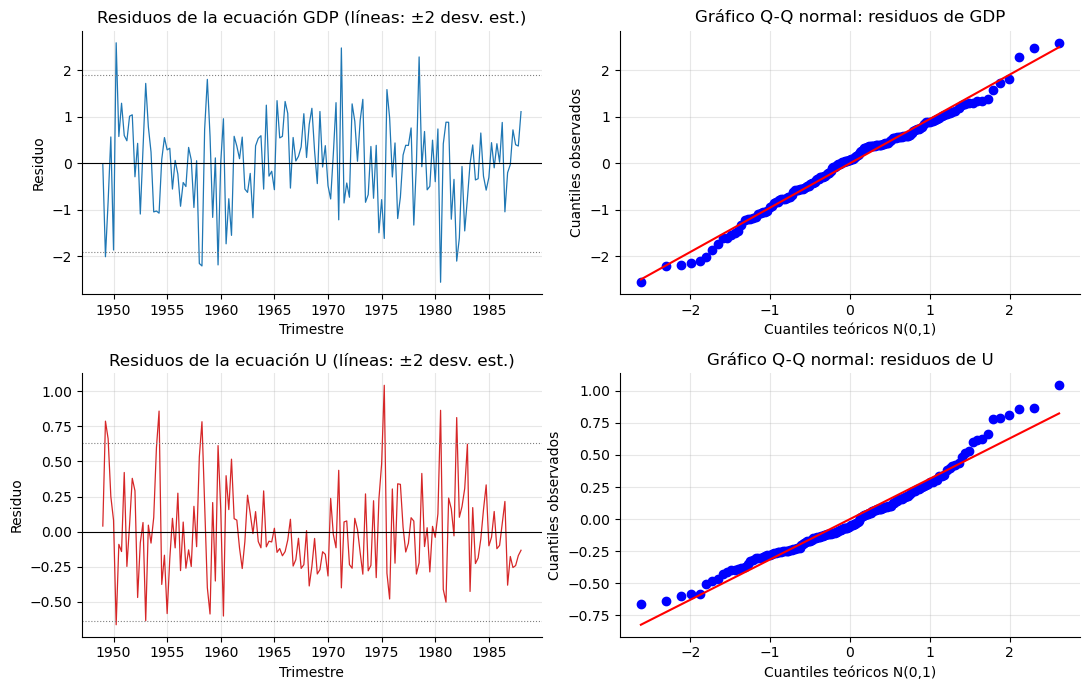

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for fila, var in enumerate(modelo.names):
    residuo = modelo.resid[var]
    ax = axes[fila, 0]
    ax.plot(residuo.index, residuo, color=COLORES[var], lw=0.9)
    for signo in (-2, 2):
        ax.axhline(signo * residuo.std(), color="gray", ls=":", lw=0.8)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=f"Residuos de la ecuación {var} (líneas: ±2 desv. est.)", xlabel="Trimestre", ylabel="Residuo")
    stats.probplot(residuo, dist="norm", plot=axes[fila, 1])
    axes[fila, 1].set(title=f"Gráfico Q-Q normal: residuos de {var}",
                      xlabel="Cuantiles teóricos N(0,1)", ylabel="Cuantiles observados")
fig.tight_layout()
plt.show()

### 12.3 Heterocedasticidad condicional (ARCH)

$$
H_0:\ \text{no hay efectos ARCH: la varianza condicional del residuo es constante}
$$

Se aplica la prueba ARCH-LM **ecuación por ecuación**, con 4 rezagos (un año). Existen versiones multivariadas, pero la prueba por ecuación es suficiente como diagnóstico inicial.

In [18]:
arch = {var: het_arch(modelo.resid[var], nlags=4) for var in modelo.names}
display(pd.DataFrame({
    var: {"Estadístico LM": r[0], "p-valor": formato_p(r[1]), "Decisión": decidir(r[1])} for var, r in arch.items()
}).T)

,Estadístico LM,p-valor,Decisión
GDP,2.3479,0.6721,No se rechaza H0
U,5.55,0.2354,No se rechaza H0


### 12.4 Resumen del diagnóstico

In [19]:
CONCLUSIONES = {
    ("Autocorrelación", False): "Sin evidencia de autocorrelación: el orden p parece capturar la dinámica",
    ("Autocorrelación", True): "Hay dinámica no capturada: considerar más rezagos o revisar la especificación",
    ("Normalidad", False): "Sin evidencia contra la normalidad",
    ("Normalidad", True): "Desviación de la normalidad: la dinámica estimada sigue siendo válida, pero los intervalos "
                          "asintóticos deben leerse con cautela (considerar bootstrap)",
    ("Heterocedasticidad", False): "Sin evidencia de efectos ARCH hasta 4 rezagos",
    ("Heterocedasticidad", True): "Varianza condicional cambiante: errores estándar e intervalos poco fiables",
}

portmanteau_8 = modelo.test_whiteness(nlags=8, adjusted=True)
pruebas = [
    ("Autocorrelación", "Sistema", "Portmanteau multivariado ajustado (h=8)",
     "No hay autocorrelación ni correlación cruzada residual hasta el rezago 8", portmanteau_8.pvalue),
    *[("Autocorrelación", var, "Ljung-Box (8 rezagos)", f"El residuo de {var} no está autocorrelacionado",
       ljung_box[var]["lb_pvalue"]) for var in modelo.names],
    ("Normalidad", "Sistema", "Jarque-Bera multivariado (Lütkepohl)",
     "Los residuos ortogonalizados son normales", normalidad_sistema.pvalue),
    *[("Normalidad", var, "Jarque-Bera univariado", f"El residuo de {var} es normal",
       jarque_bera[var].pvalue) for var in modelo.names],
    *[("Heterocedasticidad", var, "ARCH-LM (4 rezagos)", f"La varianza condicional del residuo de {var} es constante",
       arch[var][1]) for var in modelo.names],
]

resumen_diagnostico = pd.DataFrame([
    {"Supuesto": supuesto, "Alcance": alcance, "Prueba": prueba, "H0": h0, "p-valor": formato_p(p_valor),
     "Decisión": decidir(p_valor), "Conclusión": CONCLUSIONES[(supuesto, p_valor < ALPHA)]}
    for supuesto, alcance, prueba, h0, p_valor in pruebas
])
display(resumen_diagnostico.set_index(["Supuesto", "Alcance"]))

Prueba  \
Supuesto           Alcance                                            
Autocorrelación    Sistema  Portmanteau multivariado ajustado (h=8)   
                   GDP                        Ljung-Box (8 rezagos)   
                   U                          Ljung-Box (8 rezagos)   
Normalidad         Sistema     Jarque-Bera multivariado (Lütkepohl)   
                   GDP                       Jarque-Bera univariado   
                   U                         Jarque-Bera univariado   
Heterocedasticidad GDP                          ARCH-LM (4 rezagos)   
                   U                            ARCH-LM (4 rezagos)   

                                                                                                  H0  \
Supuesto           Alcance                                                                             
Autocorrelación    Sistema  No hay autocorrelación ni correlación cruzada residual hasta el rezago 8   
                   GDP                                  El residuo de GDP no está autocorrelacionado   
                   U                                      El residuo de U no está autocorrelacionado   
Normalidad         Sistema                                 Los residuos ortogonalizados son normales   
                   GDP                                                   El residuo de GDP es normal   
                   U                                                       El residuo de U es normal   
Heterocedasticidad GDP                       La varianza condicional del residuo de GDP es constante   
                   U                           La varianza condicional del residuo de U es constante   

                           p-valor          Decisión  \
Supuesto           Alcance                             
Autocorrelación    Sistema  0.2349  No se rechaza H0   
                   GDP      0.5411  No se rechaza H0   
                   U        0.0752  No se rechaza H0   
Normalidad         Sistema  0.6772  No se rechaza H0   
                   GDP      0.5776  No se rechaza H0   
                   U        0.0003     Se rechaza H0   
Heterocedasticidad GDP      0.6721  No se rechaza H0   
                   U        0.2354  No se rechaza H0   

                                                                                                                                                                        Conclusión  
Supuesto           Alcance                                                                                                                                                          
Autocorrelación    Sistema                                                                                Sin evidencia de autocorrelación: el orden p parece capturar la dinámica  
                   GDP                                                                                    Sin evidencia de autocorrelación: el orden p parece capturar la dinámica  
                   U                                                                                      Sin evidencia de autocorrelación: el orden p parece capturar la dinámica  
Normalidad         Sistema                                                                                                                      Sin evidencia contra la normalidad  
                   GDP                                                                                                                          Sin evidencia contra la normalidad  
                   U        Desviación de la normalidad: la dinámica estimada sigue siendo válida, pero los intervalos asintóticos deben leerse con cautela (considerar bootstrap)  
Heterocedasticidad GDP                                                                                                               Sin evidencia de efectos ARCH hasta 4 rezagos  
                   U                                                                                                   

### 🧠 Interprete el resultado

- **Autocorrelación:** la prueba multivariada no rechaza $H_0$ en ninguno de los horizontes evaluados, y Ljung-Box tampoco la rechaza al 5 % en ninguna ecuación (el p-valor de U está cerca del umbral, por lo que conviene no sobreinterpretarlo). El VAR(2) captura adecuadamente la dinámica lineal.
- **Normalidad:** los resultados **difieren según la prueba**. El JB univariado rechaza normalidad en el residuo de U (asimetría y colas), mientras que el JB multivariado no la rechaza. La diferencia se explica porque la prueba multivariada analiza los residuos **ortogonalizados**: la componente ortogonal asociada a U es la parte de la innovación de U no explicada por la de GDP, y su asimetría y curtosis son menores (ver la tabla de 12.2). Conclusión prudente: hay **indicios de no normalidad** en la ecuación del desempleo.
- **ARCH:** no hay evidencia de heterocedasticidad condicional en ninguna ecuación.

### ⚠️ Cuidado con esta conclusión

> "No se rechaza $H_0$" no significa "el supuesto se cumple": significa que con estos datos y esta prueba no hay evidencia suficiente en su contra. Además, aplicar muchas pruebas a la vez aumenta la probabilidad de algún rechazo por azar.

## 13. Causalidad de Granger

### ¿Qué queremos saber?
Si el **pasado** de una variable $X$ mejora el pronóstico de $Y$ más allá de lo que ya aporta el pasado de $Y$ (y de las demás variables del sistema). Granger (1969) formalizó esta noción.

### Hipótesis
En la ecuación de $Y$ se prueban **conjuntamente** todos los coeficientes de los rezagos de $X$. Por ejemplo, para U → GDP en el VAR(2):

$$
H_0:\ X \text{ no causa en el sentido de Granger a } Y
\quad\Longleftrightarrow\quad
H_0:\ \phi_{12} = \phi_{14} = 0 \ \text{ en la ecuación de } GDP .
$$

Se usa una prueba $F$ (tipo Wald) con $p$ restricciones.

> ### ⚠️ Advertencia fundamental
> **Causalidad de Granger significa capacidad predictiva adicional y NO demuestra causalidad científica, estructural o de intervención.** Una variable puede "causar en el sentido de Granger" a otra simplemente porque reacciona antes a un tercer factor común (por ejemplo, expectativas).

### 💡 Piense antes de ejecutar

> En la ecuación del desempleo, `L1.GDP` resultó significativo individualmente. Si los rezagos de GDP son significativos **conjuntamente** en la ecuación de desempleo, ¿qué esperaría encontrar en la prueba de Granger GDP → U?

In [20]:
filas = []
for causa, efecto in [("GDP", "U"), ("U", "GDP")]:
    prueba = modelo.test_causality(caused=efecto, causing=causa, kind="f")
    rechaza = prueba.pvalue < ALPHA
    filas.append({
        "Dirección": f"{causa} → {efecto}",
        "H0": f"Los {p_opt} rezagos de {causa} no ayudan a predecir {efecto}",
        "Estadístico F": round(prueba.test_statistic, 3),
        "gl": prueba.df,
        "p-valor": formato_p(prueba.pvalue),
        "Decisión": decidir(prueba.pvalue),
        "Interpretación": (f"El pasado de {causa} aporta información predictiva sobre {efecto}, adicional a la historia de {efecto}"
                           if rechaza else f"Sin evidencia de que el pasado de {causa} mejore la predicción de {efecto}"),
        "_rechaza": rechaza,
    })
granger = pd.DataFrame(filas).set_index("Dirección")
display(granger.drop(columns="_rechaza"))

if granger["_rechaza"].all():
    print("Resultado: hay causalidad de Granger en ambas direcciones (retroalimentación predictiva).")
elif granger["_rechaza"].any():
    print("Resultado: causalidad de Granger unidireccional:", granger.index[granger["_rechaza"]][0])
else:
    print("Resultado: no hay evidencia de causalidad de Granger en ninguna dirección.")

,H0,Estadístico F,gl,p-valor,Decisión,Interpretación
Dirección,,,,,,
GDP → U,Los 2 rezagos de GDP no ayudan a predecir U,5.572,"(2, 304)",0.0042,Se rechaza H0,"El pasado de GDP aporta información predictiva sobre U, adicional a la historia de U"
U → GDP,Los 2 rezagos de U no ayudan a predecir GDP,12.821,"(2, 304)",< 0.0001,Se rechaza H0,"El pasado de U aporta información predictiva sobre GDP, adicional a la historia de GDP"


Resultado: hay causalidad de Granger en ambas direcciones (retroalimentación predictiva).


### Granger, correlación contemporánea y causalidad estructural

La prueba de Granger solo mira **rezagos**. Lo que ocurre **dentro del mismo trimestre** queda en la correlación de las innovaciones. `statsmodels` ofrece `test_inst_causality`, que contrasta

$$
H_0:\ \operatorname{Cov}(\varepsilon_{GDP,t},\varepsilon_{U,t}) = 0 .
$$

Aunque la función se llama "causalidad instantánea", la prueba es **simétrica**: da el mismo resultado si se intercambian las variables y, por tanto, **no puede indicar dirección**. Rechazar $H_0$ solo indica que las innovaciones están **correlacionadas contemporáneamente**.

In [21]:
instantanea = modelo.test_inst_causality(causing="GDP")
print(f"Correlación contemporánea de las innovaciones: {modelo.resid_corr[0, 1]:.3f}")
print(f"Prueba de correlación contemporánea (Wald): estadístico = {instantanea.test_statistic:.2f}, "
      f"p-valor = {formato_p(instantanea.pvalue)} → {decidir(instantanea.pvalue)}")

Correlación contemporánea de las innovaciones: -0.656
Prueba de correlación contemporánea (Wald): estadístico = 47.21, p-valor = < 0.0001 → Se rechaza H0


| Concepto | Pregunta que responde | ¿Qué permite concluir? |
|---|---|---|
| **Causalidad de Granger** | ¿El pasado de $X$ mejora el pronóstico de $Y$? | Precedencia temporal y capacidad predictiva |
| **Correlación contemporánea de residuos** | ¿Las sorpresas de $X$ y $Y$ ocurren juntas en el mismo periodo? | Asociación instantánea, **sin dirección** |
| **Causalidad estructural** | ¿Qué le ocurre a $Y$ si se interviene $X$? | Efectos causales, **solo** bajo supuestos de identificación justificados (SVAR, experimentos, instrumentos) |

### 🧠 Interprete el resultado

- **Resultado estadístico:** se rechaza $H_0$ en ambas direcciones, y las innovaciones están fuertemente correlacionadas en el mismo trimestre.
- **Interpretación:** el pasado del crecimiento ayuda a predecir el desempleo y el pasado del desempleo ayuda a predecir el crecimiento: hay **retroalimentación predictiva**. Modelar las dos series conjuntamente es útil para pronosticar.
- **Limitación:** nada de lo anterior indica qué variable "mueve" a la otra en sentido económico. Ambas podrían responder a shocks comunes (demanda agregada, productividad, política monetaria) no incluidos en el sistema.

## 14. Funciones impulso-respuesta (IRF)

### ¿Qué queremos saber?
Cómo se propaga en el tiempo una perturbación inesperada en una variable sobre todas las variables del sistema.

### Conceptos clave

| Concepto | Significado |
|---|---|
| **Shock (impulso)** | Una innovación inesperada $\varepsilon_t$ en una ecuación, es decir, una sorpresa que el pasado no permitía anticipar |
| **Respuesta** | Diferencia entre la trayectoria esperada de una variable *con* el shock y *sin* él |
| **Horizonte $h$** | Trimestres transcurridos desde el shock ($h=0$ es el mismo trimestre) |
| **Volver a cero** | El efecto es transitorio; ocurre necesariamente si el VAR es estable |
| **Intervalo que incluye cero** | En ese horizonte no se distingue estadísticamente la respuesta de cero |

Como el VAR estable puede escribirse como un promedio móvil infinito, $\mathbf y_t = \boldsymbol\mu + \sum_{h\ge0}\Psi_h\boldsymbol\varepsilon_{t-h}$, la matriz $\Psi_h$ contiene las respuestas al horizonte $h$.

### El problema de identificación

Las innovaciones de GDP y U están **correlacionadas** (cerca de −0.66). Preguntar por "un shock en GDP manteniendo fijo el de U" no tiene sentido empírico, porque los dos shocks suelen ocurrir juntos. La solución habitual es **ortogonalizar** con la descomposición de Cholesky $\Sigma = PP'$, con $P$ triangular inferior, y definir shocks no correlacionados $\mathbf u_t = P^{-1}\boldsymbol\varepsilon_t$ de varianza unitaria. Las IRF ortogonalizadas son $\Theta_h = \Psi_h P$.

Con el orden de este cuaderno, `['GDP', 'U']`, el supuesto de identificación es:

- un shock en **GDP** puede afectar a **U en el mismo trimestre**;
- un shock en **U** **no** afecta a GDP en el mismo trimestre (solo a partir de $h=1$);
- toda la correlación contemporánea se atribuye al shock de la variable ordenada primero.

**Las IRF ortogonalizadas por Cholesky dependen del orden de las variables.** El tamaño del shock es **una desviación estándar** de la innovación ortogonalizada.

> **Nota técnica:** `irf.plot()` usa por defecto `orth=False`, es decir, IRF **no ortogonalizadas** (un shock de una unidad en $\varepsilon$ que ignora su correlación con las demás innovaciones). Las gráficas de la versión anterior del cuaderno eran de ese tipo, y su respuesta en $h=0$ era cero por construcción. Aquí usamos explícitamente la versión ortogonalizada.

### 💡 Piense antes de ejecutar

> Si ocurre un shock positivo en GDP, ¿qué dirección esperaría inicialmente en la respuesta del desempleo? ¿Y cuánto debería tardar en desaparecer, dado el autovalor dominante de la sección 11?

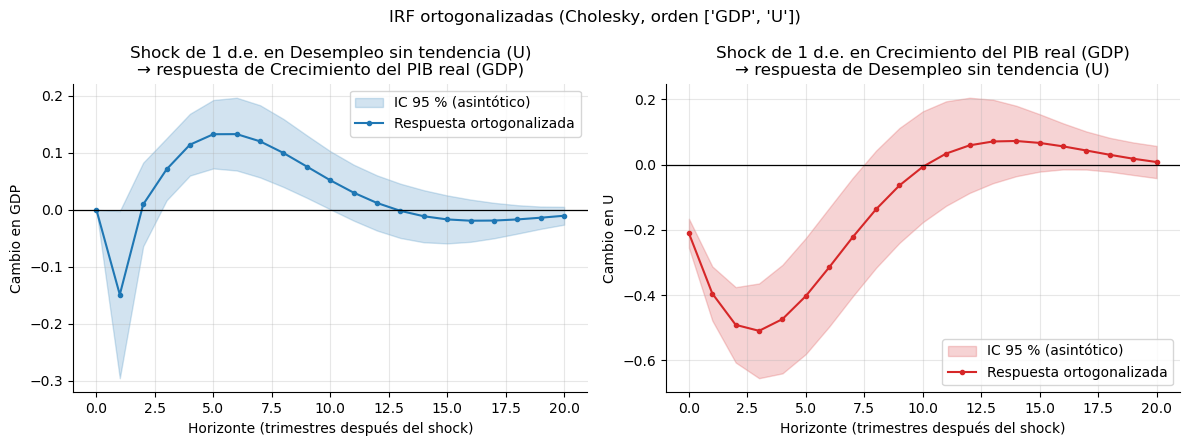

In [22]:
H_IRF = 20
Z = stats.norm.ppf(1 - ALPHA / 2)


def respuesta_ortogonal(resultado, impulso, respuesta, horizonte=H_IRF):
    """IRF ortogonalizada (Cholesky, según el orden de columnas del modelo) y su error estándar asintótico."""
    irf_ = resultado.irf(horizonte)
    i, j = resultado.names.index(respuesta), resultado.names.index(impulso)
    return irf_.orth_irfs[:, i, j], irf_.stderr(orth=True)[:, i, j]


def graficar_irf(ax, impulso, respuesta, resultado=modelo):
    valores, error = respuesta_ortogonal(resultado, impulso, respuesta)
    h = np.arange(len(valores))
    ax.fill_between(h, valores - Z * error, valores + Z * error, color=COLORES[respuesta], alpha=0.2, label="IC 95 % (asintótico)")
    ax.plot(h, valores, color=COLORES[respuesta], marker="o", ms=3, label="Respuesta ortogonalizada")
    ax.axhline(0, color="black", lw=0.9)
    ax.set(title=f"Shock de 1 d.e. en {NOMBRES[impulso]}\n→ respuesta de {NOMBRES[respuesta]}",
           xlabel="Horizonte (trimestres después del shock)", ylabel=f"Cambio en {respuesta}")
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
graficar_irf(axes[0], impulso="U", respuesta="GDP")
graficar_irf(axes[1], impulso="GDP", respuesta="U")
fig.suptitle(f"IRF ortogonalizadas (Cholesky, orden {modelo.names})", fontsize=12)
fig.tight_layout()
plt.show()

In [23]:
def rangos(horizontes):
    """Convierte [1,2,3,7,8] en '1–3, 7–8'."""
    if len(horizontes) == 0:
        return "ninguno"
    grupos, inicio, previo = [], horizontes[0], horizontes[0]
    for h in list(horizontes[1:]) + [None]:
        if h is None or h != previo + 1:
            grupos.append(f"{inicio}" if inicio == previo else f"{inicio}–{previo}")
            inicio = h
        previo = h
    return ", ".join(grupos)


def resumir_irf(impulso, respuesta, resultado=modelo):
    valores, error = respuesta_ortogonal(resultado, impulso, respuesta)
    h_max = int(np.argmax(np.abs(valores)))
    significativos = np.where((valores - Z * error > 0) | (valores + Z * error < 0))[0]
    return {
        "Shock → respuesta": f"{impulso} → {respuesta}",
        "Impacto (h=0)": valores[0],
        "Efecto de mayor magnitud": valores[h_max],
        "Horizonte de ese efecto": h_max,
        "Horizontes con IC que excluye 0": rangos(significativos),
        f"Respuesta en h={H_IRF}": valores[-1],
    }


resumen_irf = pd.DataFrame([resumir_irf("U", "GDP"), resumir_irf("GDP", "U")]).set_index("Shock → respuesta")
display(resumen_irf.round(3))

,Impacto (h=0),Efecto de mayor magnitud,Horizonte de ese efecto,Horizontes con IC que excluye 0,Respuesta en h=20
Shock → respuesta,,,,,
U → GDP,0.00,-0.149,1,"1, 3–10",-0.010
GDP → U,-0.21,-0.509,3,0–7,0.008


### 🧠 Interprete el resultado (bajo el orden GDP → U)

**Shock en GDP → respuesta de U**

- **Resultado:** el desempleo **disminuye** desde el mismo trimestre del shock (la identificación lo permite), la caída se profundiza durante los primeros trimestres, alcanza su máximo hacia el tercer trimestre y luego regresa gradualmente hacia cero. El IC excluye el cero durante aproximadamente los dos primeros años; después aparece un leve rebote positivo cuyo IC incluye el cero (ver la tabla para los valores exactos).
- **Interpretación:** una sorpresa positiva en el crecimiento se asocia con una reducción persistente pero transitoria del desempleo, coherente con la ley de Okun.

**Shock en U → respuesta de GDP**

- **Resultado:** la respuesta en $h=0$ es **exactamente cero por construcción** (GDP está ordenado primero). En $h=1$ el crecimiento cae, y es su efecto de mayor magnitud; después la respuesta se vuelve positiva durante varios trimestres y finalmente se desvanece. Según la tabla, tanto la caída inicial como el rebote positivo de los trimestres siguientes tienen IC que excluyen el cero; en $h=2$, cuando la respuesta cambia de signo, el IC sí incluye el cero.
- **Interpretación:** tras un aumento inesperado del desempleo, el crecimiento cae en el corto plazo y luego presenta un rebote compensatorio. Recuerde que las bandas son asintóticas y que la ecuación de U mostró indicios de no normalidad.

En ambos casos las respuestas vuelven a cero, como corresponde a un VAR estable.

### ⚠️ Cuidado con esta conclusión

> Estas IRF describen la respuesta **condicionada a la identificación de Cholesky con orden GDP → U**. No permiten afirmar que "un aumento del PIB **causa** una caída del desempleo de tal magnitud". Esa lectura estructural requeriría justificar la identificación con teoría económica.

### 14.1 ¿Qué cambia si invertimos el orden de las variables?

Re-estimamos el mismo VAR con el orden `['U', 'GDP']`. Los coeficientes y los pronósticos **no cambian**: es el mismo modelo en forma reducida. Lo que cambia es la **ortogonalización** de los shocks. Incluimos también la IRF no ortogonalizada (`orth=False`) como referencia.

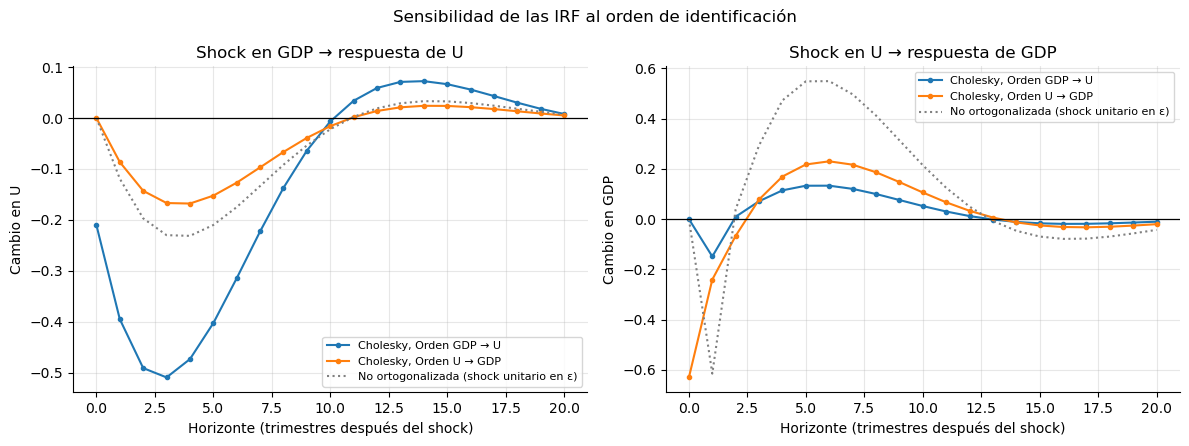

Respuesta en el impacto (h = 0):


,Orden GDP → U,Orden U → GDP
Shock GDP → U,-0.21,0.00
Shock U → GDP,0.00,-0.63


In [24]:
modelo_invertido = VAR(datos[["U", "GDP"]]).fit(p_opt)
assert np.allclose(modelo_invertido.fittedvalues[["GDP", "U"]], modelo.fittedvalues), "La forma reducida debería ser idéntica"

irf_no_ortogonal = modelo.irf(H_IRF).irfs
h = np.arange(H_IRF + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (impulso, respuesta) in zip(axes, [("GDP", "U"), ("U", "GDP")]):
    for resultado, etiqueta, color in [(modelo, "Orden GDP → U", "C0"), (modelo_invertido, "Orden U → GDP", "C1")]:
        valores, _ = respuesta_ortogonal(resultado, impulso, respuesta)
        ax.plot(h, valores, marker="o", ms=3, color=color, label=f"Cholesky, {etiqueta}")
    i, j = modelo.names.index(respuesta), modelo.names.index(impulso)
    ax.plot(h, irf_no_ortogonal[:, i, j], ls=":", color="gray", label="No ortogonalizada (shock unitario en ε)")
    ax.axhline(0, color="black", lw=0.9)
    ax.set(title=f"Shock en {impulso} → respuesta de {respuesta}",
           xlabel="Horizonte (trimestres después del shock)", ylabel=f"Cambio en {respuesta}")
    ax.legend(fontsize=8)
fig.suptitle("Sensibilidad de las IRF al orden de identificación", fontsize=12)
fig.tight_layout()
plt.show()

impacto = pd.DataFrame({
    "Orden GDP → U": [respuesta_ortogonal(modelo, i, r)[0][0] for i, r in [("GDP", "U"), ("U", "GDP")]],
    "Orden U → GDP": [respuesta_ortogonal(modelo_invertido, i, r)[0][0] for i, r in [("GDP", "U"), ("U", "GDP")]],
}, index=["Shock GDP → U", "Shock U → GDP"])
print("Respuesta en el impacto (h = 0):")
display(impacto.round(3))

### 🔎 ¿Qué observa?

- Con el orden **GDP → U**, el shock en GDP afecta a U en el impacto y el shock en U no afecta a GDP en $h=0$. Con el orden **U → GDP** ocurre exactamente lo contrario: la correlación contemporánea de −0.66 se "asigna" ahora al shock de desempleo.
- La forma general de las respuestas se mantiene, pero **la magnitud cambia de manera importante**, sobre todo en el corto plazo.
- Como la correlación de las innovaciones es alta, el orden **sí importa** en este ejemplo. Si la correlación fuera cercana a cero, las dos ortogonalizaciones prácticamente coincidirían.

### ⚠️ Cuidado con esta conclusión

> Elegir el orden "que da resultados más razonables" no es una identificación válida. El orden debe justificarse *antes* de mirar los resultados, por ejemplo con el argumento de que una variable reacciona con rezago a la otra. Blanchard y Quah (1989) evitaron precisamente esta arbitrariedad imponiendo restricciones de largo plazo (SVAR).

## 15. Descomposición de la varianza del error de pronóstico (FEVD)

### ¿Qué queremos saber?

> La FEVD responde **qué proporción de la incertidumbre del pronóstico de una variable puede atribuirse a cada innovación del sistema**.

El error de pronóstico a $h$ pasos es una combinación de los shocks ortogonales que ocurrirán entre $T+1$ y $T+h$. Como esos shocks no están correlacionados, la varianza del error se reparte en contribuciones de cada shock que **suman 100 %**:

$$
\omega_{ij}(h) = \frac{\sum_{s=0}^{h-1} \theta_{ij,s}^2}{\sum_{s=0}^{h-1}\sum_{m=1}^{k} \theta_{im,s}^2},
$$

donde $\theta_{ij,s}$ es la IRF ortogonalizada de la variable $i$ ante el shock $j$ en el horizonte $s$.

En `statsmodels`, `fevd.decomp[i, h-1, j]` contiene $\omega_{ij}(h)$. Leemos los porcentajes **directamente de ese arreglo**, no estimándolos a ojo desde el gráfico.

**Advertencia:** al usar shocks ortogonalizados por Cholesky, la FEVD **también depende del orden de identificación**. En particular, a $h=1$ la variable ordenada primero se atribuye el 100 % de su propia varianza por construcción.

In [25]:
H_FEVD = 10
HORIZONTES = [1, 4, 8, 10]


def tabla_fevd(resultado, variable, horizontes=HORIZONTES):
    fevd_ = resultado.fevd(H_FEVD)
    i = resultado.names.index(variable)
    tabla = pd.DataFrame(fevd_.decomp[i] * 100,
                         index=pd.Index(range(1, H_FEVD + 1), name="Horizonte (trimestres)"),
                         columns=[f"Shock {n} (%)" for n in resultado.names])
    tabla["Total (%)"] = tabla.sum(axis=1)
    return tabla.loc[horizontes]


tablas_fevd = {}
for var in modelo.names:
    tablas_fevd[var] = tabla_fevd(modelo, var)
    display(Markdown(f"**Varianza del error de pronóstico de {NOMBRES[var]}** (orden {modelo.names})"))
    display(tablas_fevd[var].round(1))

**Varianza del error de pronóstico de Crecimiento del PIB real (GDP)** (orden ['GDP', 'U'])

,Shock GDP (%),Shock U (%),Total (%)
Horizonte (trimestres),,,
1,100.0,0.0,100.0
4,97.3,2.7,100.0
8,92.4,7.6,100.0
10,91.5,8.5,100.0


**Varianza del error de pronóstico de Desempleo sin tendencia (U)** (orden ['GDP', 'U'])

,Shock GDP (%),Shock U (%),Total (%)
Horizonte (trimestres),,,
1,43.0,57.0,100.0
4,64.0,36.0,100.0
8,68.4,31.6,100.0
10,68.7,31.3,100.0


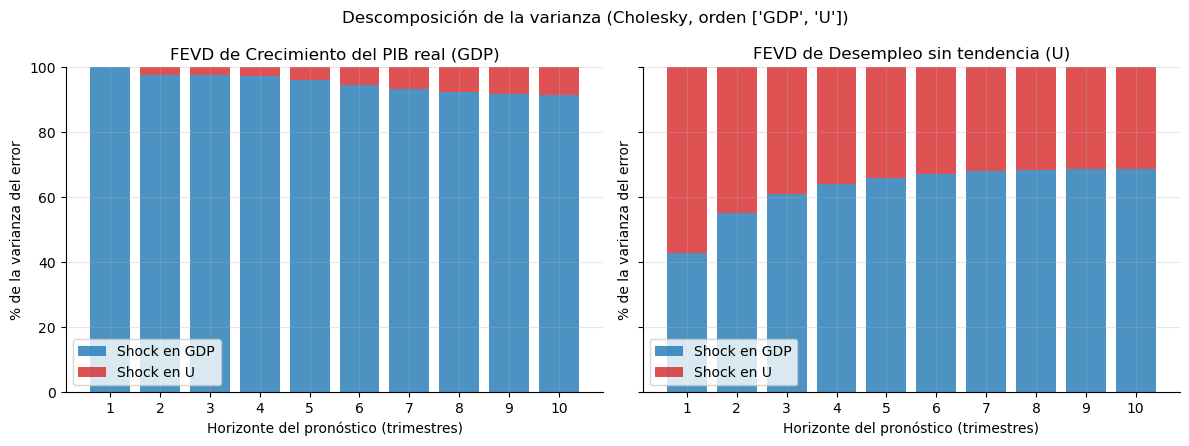

In [26]:
fevd = modelo.fevd(H_FEVD)
horizontes = np.arange(1, H_FEVD + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, var in zip(axes, modelo.names):
    i = modelo.names.index(var)
    base = np.zeros(H_FEVD)
    for j, shock in enumerate(modelo.names):
        aporte = fevd.decomp[i, :, j] * 100
        ax.bar(horizontes, aporte, bottom=base, color=COLORES[shock], alpha=0.8, label=f"Shock en {shock}")
        base += aporte
    ax.set(title=f"FEVD de {NOMBRES[var]}", xlabel="Horizonte del pronóstico (trimestres)",
           ylabel="% de la varianza del error", ylim=(0, 100), xticks=horizontes)
    ax.legend(loc="lower left")
fig.suptitle(f"Descomposición de la varianza (Cholesky, orden {modelo.names})", fontsize=12)
fig.tight_layout()
plt.show()

In [27]:
# Sensibilidad de la FEVD al orden: % de la varianza de cada variable atribuido al shock de la OTRA variable
comparacion = {}
for var, otra in [("GDP", "U"), ("U", "GDP")]:
    comparacion[(f"{var}: % por shock en {otra}", "Orden GDP → U")] = tabla_fevd(modelo, var)[f"Shock {otra} (%)"]
    comparacion[(f"{var}: % por shock en {otra}", "Orden U → GDP")] = tabla_fevd(modelo_invertido, var)[f"Shock {otra} (%)"]
display(pd.DataFrame(comparacion).round(1))

GDP: % por shock en U                \
                               Orden GDP → U Orden U → GDP   
Horizonte (trimestres)                                       
1                                        0.0          43.0   
4                                        2.7          46.4   
8                                        7.6          53.9   
10                                       8.5          55.7   

                       U: % por shock en GDP                
                               Orden GDP → U Orden U → GDP  
Horizonte (trimestres)                                      
1                                       43.0           0.0  
4                                       64.0           5.1  
8                                       68.4           7.3  
10                                      68.7           7.6

### 🧠 Interprete el resultado

Las lecturas siguientes se refieren a las tablas generadas arriba (orden GDP → U):

- **Crecimiento del PIB:** a un trimestre, el 100 % de la incertidumbre del pronóstico se atribuye a su propio shock, en parte **por construcción** (GDP está ordenado primero). La contribución del shock de desempleo crece con el horizonte, pero se mantiene por debajo del 10 % a 10 trimestres. Bajo esta identificación, la incertidumbre sobre el crecimiento futuro proviene principalmente de sus propias innovaciones.
- **Desempleo:** ya a un trimestre, una fracción importante, aunque **menor que la mitad**, de su incertidumbre se atribuye al shock de GDP, y esa fracción **aumenta** con el horizonte hasta superar dos tercios a 8–10 trimestres. A medio plazo, bajo este orden, la mayor parte de la incertidumbre del desempleo se asocia a las innovaciones del crecimiento.
- En todas las filas la columna *Total* suma 100 %.

### ⚠️ Cuidado con esta conclusión

> La tabla comparativa muestra que, con el orden **U → GDP**, el desempleo pasa a explicar la mayor parte de su propia varianza y es el crecimiento del PIB el que recibe una contribución grande del otro shock. Con innovaciones tan correlacionadas, **la FEVD no puede interpretarse sin defender la identificación**. Afirmaciones como "el PIB explica el 70 % del desempleo" son, en el mejor de los casos, condicionales a un supuesto discutible.

## 16. Pronóstico

### ¿Cómo pronostica un VAR?

El pronóstico se construye de forma **recursiva**: los valores futuros desconocidos se reemplazan por sus propios pronósticos,

$$
\hat{\mathbf y}_{T+h\mid T} = \hat{\mathbf c} + \hat A_1\hat{\mathbf y}_{T+h-1\mid T} + \cdots + \hat A_p\hat{\mathbf y}_{T+h-p\mid T},
\qquad \hat{\mathbf y}_{T+j\mid T} = \mathbf y_{T+j}\ \text{si } j\le 0 .
$$

La matriz de error cuadrático medio $\Sigma_y(h) = \sum_{s=0}^{h-1}\Psi_s\Sigma\Psi_s'$ crece con $h$, por lo que los intervalos se ensanchan. En un VAR estable, el pronóstico converge a la media incondicional $\boldsymbol\mu$ y los intervalos se estabilizan en la varianza incondicional.

### Evaluación fuera de muestra

Antes de confiar en el pronóstico futuro, simulamos la situación real:

1. reservamos los **últimos 8 trimestres** como conjunto de prueba;
2. seleccionamos $p$ y estimamos el VAR **solo** con el conjunto de entrenamiento;
3. pronosticamos esos 8 trimestres y comparamos con lo observado.

Entrenamiento: 1948Q2–1985Q4 (151 obs.) | Prueba: 1986Q1–1987Q4
Orden en entrenamiento: VAR(2) — todos los criterios coinciden en p = 2.


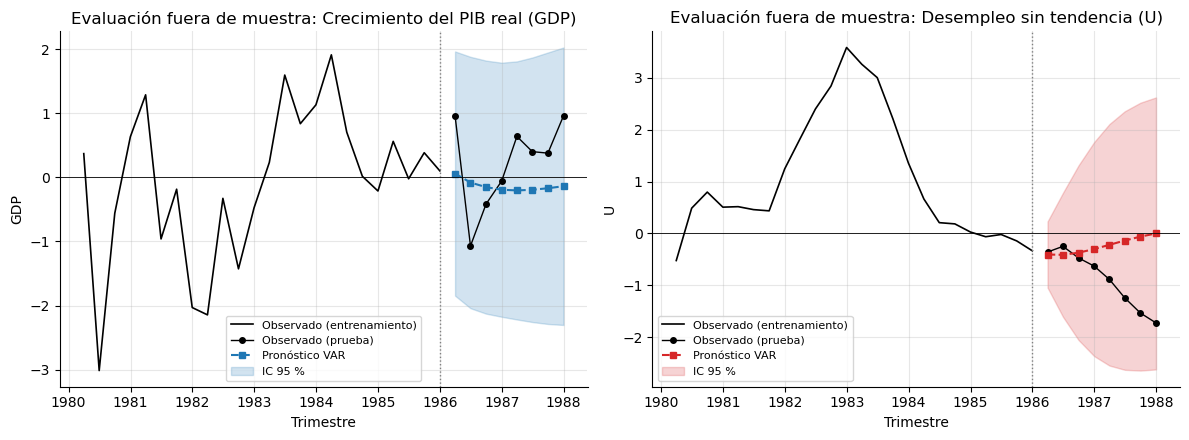

In [28]:
H_PRONOSTICO = 8
entrenamiento, prueba = datos.iloc[:-H_PRONOSTICO], datos.iloc[-H_PRONOSTICO:]

p_entrenamiento, _, motivo_entrenamiento = elegir_orden(VAR(entrenamiento).select_order(maxlags=12))
modelo_entrenamiento = VAR(entrenamiento).fit(p_entrenamiento)
print(f"Entrenamiento: {entrenamiento.index[0].to_period('Q')}–{entrenamiento.index[-1].to_period('Q')} "
      f"({len(entrenamiento)} obs.) | Prueba: {prueba.index[0].to_period('Q')}–{prueba.index[-1].to_period('Q')}")
print(f"Orden en entrenamiento: VAR({p_entrenamiento}) — {motivo_entrenamiento}.")

media, inferior, superior = modelo_entrenamiento.forecast_interval(
    entrenamiento.values[-p_entrenamiento:], steps=H_PRONOSTICO, alpha=ALPHA
)
pron_prueba = pd.DataFrame(media, index=prueba.index, columns=datos.columns)
inf_prueba = pd.DataFrame(inferior, index=prueba.index, columns=datos.columns)
sup_prueba = pd.DataFrame(superior, index=prueba.index, columns=datos.columns)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, var in zip(axes, datos.columns):
    historia = entrenamiento[var].iloc[-24:]
    ax.plot(historia.index, historia, color="black", lw=1.2, label="Observado (entrenamiento)")
    ax.plot(prueba.index, prueba[var], color="black", marker="o", ms=4, ls="-", lw=1, label="Observado (prueba)")
    ax.plot(pron_prueba.index, pron_prueba[var], color=COLORES[var], ls="--", marker="s", ms=4, label="Pronóstico VAR")
    ax.fill_between(prueba.index, inf_prueba[var], sup_prueba[var], color=COLORES[var], alpha=0.2, label="IC 95 %")
    ax.axvline(entrenamiento.index[-1], color="gray", ls=":", lw=1)
    ax.axhline(0, color="black", lw=0.6)
    ax.set(title=f"Evaluación fuera de muestra: {NOMBRES[var]}", xlabel="Trimestre", ylabel=var)
    ax.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()

## 17. Evaluación del pronóstico

Calculamos, por variable:

$$
\text{MAE} = \frac{1}{H}\sum_{h=1}^{H}\left|y_{T+h}-\hat y_{T+h\mid T}\right|,
\qquad
\text{RMSE} = \sqrt{\frac{1}{H}\sum_{h=1}^{H}\left(y_{T+h}-\hat y_{T+h\mid T}\right)^2}.
$$

Un error aislado no dice mucho, así que lo comparamos con dos **pronósticos de referencia** sencillos: el **ingenuo** (repetir el último valor observado) y la **media** del entrenamiento. Reportamos también la **cobertura** empírica del IC 95 %.

**¿Y el MAPE?** El MAPE divide por $|y_t|$. Ambas series son desviaciones que oscilan alrededor de cero, de modo que valores cercanos a cero harían explotar el indicador. La celda verifica esto antes de decidir.

In [29]:
def metricas(observado, pronostico):
    error = observado - pronostico
    return {"MAE": error.abs().mean(), "RMSE": np.sqrt((error ** 2).mean())}


referencias = {
    "VAR": pron_prueba,
    "Ingenuo (último valor)": pd.DataFrame(np.tile(entrenamiento.iloc[-1].values, (H_PRONOSTICO, 1)),
                                           index=prueba.index, columns=datos.columns),
    "Media de entrenamiento": pd.DataFrame(np.tile(entrenamiento.mean().values, (H_PRONOSTICO, 1)),
                                           index=prueba.index, columns=datos.columns),
}

filas = []
for var in datos.columns:
    for nombre, pron in referencias.items():
        fila = {"Variable": var, "Modelo": nombre, **metricas(prueba[var], pron[var])}
        if nombre == "VAR":
            dentro = (prueba[var] >= inf_prueba[var]) & (prueba[var] <= sup_prueba[var])
            fila["Cobertura IC 95 %"] = f"{dentro.sum()}/{H_PRONOSTICO}"
        filas.append(fila)
evaluacion = pd.DataFrame(filas).set_index(["Variable", "Modelo"])
display(evaluacion.round(3).fillna("—"))

for var in datos.columns:
    mejor = evaluacion.loc[var, "RMSE"].idxmin()
    print(f"{var}: menor RMSE → {mejor}")

# Pertinencia del MAPE: exige una escala con cero natural y valores alejados de cero
print()
for var in datos.columns:
    cambia_signo = (datos[var] > 0).any() and (datos[var] < 0).any()
    print(f"{var}: min |y| en prueba = {prueba[var].abs().min():.3f}; la serie "
          + ("cambia de signo (es una desviación sin cero natural) → MAPE NO es adecuado"
             if cambia_signo else "no cambia de signo → el MAPE podría usarse con cautela"))

MAE   RMSE Cobertura IC 95 %
Variable Modelo                                                
GDP      VAR                     0.673  0.747               8/8
         Ingenuo (último valor)  0.586  0.672                 —
         Media de entrenamiento  0.615  0.702                 —
U        VAR                     0.701  0.933               8/8
         Ingenuo (último valor)  0.574  0.759                 —
         Media de entrenamiento  0.933  1.069                 —

GDP: menor RMSE → Ingenuo (último valor)
U: menor RMSE → Ingenuo (último valor)

GDP: min |y| en prueba = 0.056; la serie cambia de signo (es una desviación sin cero natural) → MAPE NO es adecuado
U: min |y| en prueba = 0.248; la serie cambia de signo (es una desviación sin cero natural) → MAPE NO es adecuado


### 🧠 Interprete el resultado

- **Resultado:** la tabla compara MAE y RMSE del VAR con las dos referencias para cada variable, y reporta cuántas observaciones de prueba caen dentro del IC 95 %.
- **Resultado en esta ventana (1986T1–1987T4):** el VAR **no supera al pronóstico ingenuo** en ninguna de las dos variables. Para el desempleo sí mejora claramente a la media de entrenamiento; para el crecimiento del PIB no mejora a ninguna referencia. Las 8 observaciones de prueba de cada variable caen dentro del IC 95 %.
- **Interpretación:** en este periodo concreto, la dinámica estimada no se tradujo en mejores pronósticos puntuales. El desempleo de 1986–1987 descendió de forma sostenida, mientras que el VAR, por ser estable, pronostica un retorno hacia la media; el ingenuo, al "congelar" el último valor, quedó más cerca. Que la cobertura sea completa indica que la incertidumbre está bien representada, aunque con intervalos amplios.
- **Lección:** un modelo con buen ajuste dentro de muestra y relaciones de Granger significativas **no garantiza** mejores pronósticos fuera de muestra. Siempre hay que compararlo con referencias simples.
- **Precaución:** son solo 8 observaciones de un único periodo de prueba, por lo que el resultado puede cambiar en otra ventana. Una evaluación seria usaría validación con **origen móvil** (*rolling origin*) y pruebas formales de comparación de pronósticos, como Diebold-Mariano.

### 17.1 Pronóstico final con toda la información

Habiendo evaluado el procedimiento, re-estimamos con **todos** los datos (el `modelo` de la sección 9) y pronosticamos 8 trimestres hacia adelante.

In [30]:
media, inferior, superior = modelo.forecast_interval(datos.values[-p_opt:], steps=H_PRONOSTICO, alpha=ALPHA)
indice_futuro = pd.date_range(datos.index[-1] + pd.offsets.QuarterEnd(), periods=H_PRONOSTICO, freq="QE", name="fecha")

pronostico = pd.concat({
    "Pronóstico": pd.DataFrame(media, index=indice_futuro, columns=datos.columns),
    "Límite inferior 95 %": pd.DataFrame(inferior, index=indice_futuro, columns=datos.columns),
    "Límite superior 95 %": pd.DataFrame(superior, index=indice_futuro, columns=datos.columns),
}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(pronostico.set_axis(indice_futuro.to_period("Q")).round(3))

media_incondicional = pd.Series(modelo.mean(), index=datos.columns)
print("Media incondicional del VAR (valor al que converge el pronóstico):")
print(media_incondicional.round(4).to_string())

GDP                                                    U  \
       Pronóstico Límite inferior 95 % Límite superior 95 % Pronóstico   
fecha                                                                    
1988Q1     -0.253               -2.137                1.631     -1.793   
1988Q2     -0.439               -2.384                1.506     -1.678   
1988Q3     -0.642               -2.600                1.315     -1.438   
1988Q4     -0.710               -2.673                1.254     -1.135   
1989Q1     -0.693               -2.685                1.299     -0.818   
1989Q2     -0.618               -2.657                1.421     -0.522   
1989Q3     -0.508               -2.600                1.583     -0.267   
1989Q4     -0.386               -2.524                1.752     -0.068   

                                                  
       Límite inferior 95 % Límite superior 95 %  
fecha                                             
1988Q1               -2.421               -1.164  
1988Q2               -2.859               -0.497  
1988Q3               -3.107                0.231  
1988Q4               -3.186                0.915  
1989Q1               -3.139                1.503  
1989Q2               -3.015                1.972  
1989Q3               -2.857                2.322  
1989Q4               -2.702                2.567

Media incondicional del VAR (valor al que converge el pronóstico):
GDP   -0.0297
U     -0.0368


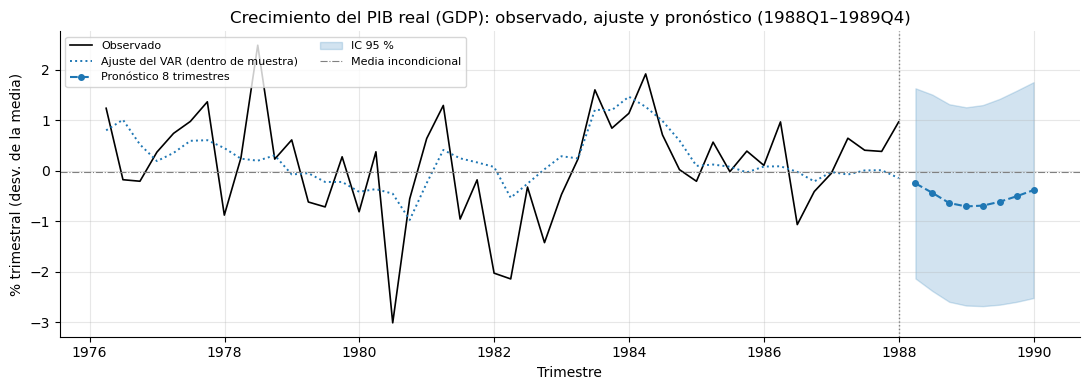

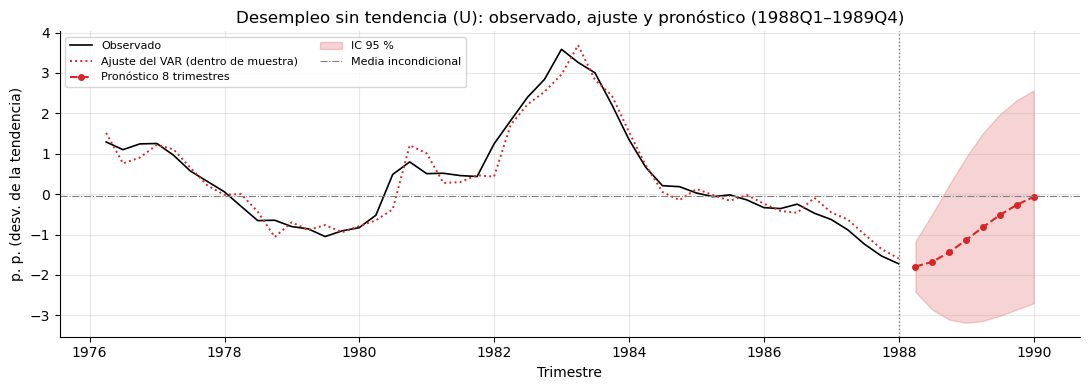

In [31]:
VENTANA = 48  # trimestres de historia mostrados para que el pronóstico sea legible
ajustados = modelo.fittedvalues

for var in datos.columns:
    fig, ax = plt.subplots(figsize=(11, 4))
    historia = datos[var].iloc[-VENTANA:]
    ax.plot(historia.index, historia, color="black", lw=1.2, label="Observado")
    ax.plot(ajustados[var].iloc[-VENTANA:].index, ajustados[var].iloc[-VENTANA:], color=COLORES[var],
            ls=":", lw=1.4, label="Ajuste del VAR (dentro de muestra)")
    ax.plot(indice_futuro, pronostico[(var, "Pronóstico")], color=COLORES[var], ls="--", marker="o", ms=4,
            label=f"Pronóstico {H_PRONOSTICO} trimestres")
    ax.fill_between(indice_futuro, pronostico[(var, "Límite inferior 95 %")], pronostico[(var, "Límite superior 95 %")],
                    color=COLORES[var], alpha=0.2, label="IC 95 %")
    ax.axvline(datos.index[-1], color="gray", ls=":", lw=1)
    ax.axhline(media_incondicional[var], color="gray", lw=0.8, ls="-.", label="Media incondicional")
    ax.set(title=f"{NOMBRES[var]}: observado, ajuste y pronóstico "
                 f"({indice_futuro[0].to_period('Q')}–{indice_futuro[-1].to_period('Q')})",
           xlabel="Trimestre", ylabel=etiquetas_y[var])
    ax.legend(fontsize=8, loc="upper left", ncol=2)
    fig.tight_layout()
    plt.show()

### 🔎 ¿Qué observa?

- El desempleo termina la muestra muy por debajo de su tendencia, y el VAR pronostica su **regreso gradual** hacia la media incondicional.
- El crecimiento pronosticado del PIB **primero se aleja** de su media (valores negativos durante el primer año) y después regresa hacia ella. Esto refleja la dinámica conjunta: con el desempleo muy por debajo de su tendencia, los rezagos de U en la ecuación de GDP (cuya suma es positiva) predicen un crecimiento inferior al promedio. Es una lectura **predictiva**, no un mecanismo causal.
- En ambas variables, el pronóstico tiende a la media incondicional a medida que avanza el horizonte, como corresponde a un VAR estable.
- Los intervalos se **ensanchan** con el horizonte y luego tienden a estabilizarse.
- El ajuste dentro de muestra sigue de cerca al desempleo (variable persistente y predecible) pero solo captura una parte de las fluctuaciones del crecimiento del PIB (variable ruidosa).

### ⚠️ Cuidado con esta conclusión

> Los intervalos suponen que el modelo es correcto y que sus parámetros son conocidos y estables. No incorporan la incertidumbre de estimación ni posibles cambios estructurales, y la evidencia de no normalidad en la ecuación de U (sección 12) sugiere leerlos como aproximados.

## 18. Limitaciones

| Limitación | Consecuencia en este análisis |
|---|---|
| **Forma reducida** | Coeficientes, Granger y pronósticos son **predictivos**; no identifican efectos causales |
| **Identificación por Cholesky** | IRF y FEVD dependen del orden, y en este ejemplo la dependencia es fuerte por la correlación de −0.66 entre innovaciones |
| **Sistema pequeño ($k=2$)** | Variables omitidas (tasa de interés, inflación, precios del petróleo) pueden generar falsa causalidad de Granger o IRF sesgadas |
| **Linealidad y parámetros constantes** | El periodo 1948–1987 incluye cambios de régimen (choques petroleros, cambios de política monetaria) que un VAR lineal no captura |
| **Transformaciones previas** | Las series ya vienen sin media y sin tendencia; los resultados dependen de esas decisiones de Blanchard y Quah |
| **Dimensionalidad** | Ampliar $k$ o $p$ dispara el número de parámetros (sección 4) |
| **Inferencia aproximada** | Los intervalos asintóticos pueden ser imprecisos con no normalidad; conviene usar bootstrap |
| **Evaluación de pronóstico limitada** | Solo 8 trimestres de prueba en un único origen |

## 19. Conclusiones

| Paso | Resultado estadístico | Interpretación | Limitación |
|---|---|---|---|
| Estacionariedad | ADF rechaza la raíz unitaria y KPSS no rechaza la estacionariedad en ambas series | Se modelan en niveles, sin diferenciar | Las pruebas tienen potencia limitada; las series ya venían transformadas |
| Orden | AIC, BIC, HQIC y FPE seleccionan el mismo orden (VAR(2) en la ejecución actual) | Dos trimestres de rezagos capturan la dinámica | Diferencias pequeñas entre órdenes cercanos |
| Estabilidad | $\lvert z\rvert>1$ en `modelo.roots`, equivalente a $\lvert\lambda\rvert<1$ en la forma compañera | Los shocks se disipan; existen IRF, FEVD y media incondicional | Raíz dominante relativamente persistente |
| Diagnóstico | Sin autocorrelación ni efectos ARCH; indicios de no normalidad en la ecuación de U | Especificación dinámica adecuada | Intervalos asintóticos aproximados |
| Granger | Se rechaza $H_0$ en ambas direcciones | Retroalimentación **predictiva** entre crecimiento y desempleo | No implica causalidad estructural |
| IRF | Shock en GDP → U cae y regresa a cero; shock en U → GDP cae a corto plazo y rebota | Dinámica coherente con la ley de Okun | Condicional a Cholesky con orden GDP → U; cambia al invertir el orden |
| FEVD | Bajo GDP → U, el shock de GDP domina la incertidumbre del pronóstico de U a medio plazo | Asociación dinámica fuerte del crecimiento con el desempleo futuro | Altamente sensible al orden de identificación |
| Pronóstico | Fuera de muestra (1986–1987) no supera al ingenuo, aunque la cobertura del IC 95 % es completa; el pronóstico futuro converge a la media incondicional | La capacidad predictiva dentro de muestra no garantiza ganancias fuera de muestra | Evaluación con pocos datos y un único origen |

**Mensaje central:** el VAR es una herramienta poderosa para describir y pronosticar la dinámica conjunta de varias series. Pasar de la **descripción predictiva** a la **interpretación causal** exige supuestos de identificación explícitos y defendibles, que es el tema de los modelos SVAR.

### Referencias

- Blanchard, O. J., y Quah, D. (1989). The dynamic effects of aggregate demand and supply disturbances. *American Economic Review*, 79(4), 655–673.
- Granger, C. W. J. (1969). Investigating causal relations by econometric models and cross-spectral methods. *Econometrica*, 37(3), 424–438.
- Lütkepohl, H. (2005). *New Introduction to Multiple Time Series Analysis*. Springer.
- Sims, C. A. (1980). Macroeconomics and reality. *Econometrica*, 48(1), 1–48.
- Tsay, R. S. (2014). *Multivariate Time Series Analysis: With R and Financial Applications*. Wiley.

## 20. Actividad para el estudiante

Responda con base en los resultados de este cuaderno. Justifique cada respuesta distinguiendo **resultado estadístico → interpretación → limitación**.

1. **Granger frente a coeficientes.** En la ecuación de GDP, `L1.U` y `L2.U` tienen signos opuestos. ¿Por qué la prueba de Granger U → GDP es más informativa que mirar cada coeficiente por separado? ¿Qué concluiría si ambos coeficientes fueran individualmente no significativos pero la prueba conjunta rechazara $H_0$?

2. **Estabilidad.** Un compañero afirma: "el VAR es inestable porque `modelo.roots` tiene valores mayores que 1". Explique su error y relacione las raíces $z$ con los autovalores $\lambda$ de la forma compañera.

3. **Identificación.** Con el orden GDP → U, la respuesta de GDP a un shock de U en $h=0$ es exactamente cero. ¿Es esto un hallazgo empírico o un supuesto? ¿Qué argumento económico podría justificar ordenar primero el PIB? ¿Y primero el desempleo?

4. **FEVD.** Redacte dos frases sobre la FEVD del desempleo a 8 trimestres: una que sobreinterprete el resultado y otra que lo comunique correctamente, mencionando el supuesto de identificación.

5. **Pronóstico.** En la evaluación fuera de muestra el VAR no superó al pronóstico ingenuo, pese a que la causalidad de Granger fue significativa en ambas direcciones. ¿Es esto contradictorio? ¿Por qué un único periodo de prueba de 8 trimestres no basta para concluir que el VAR pronostica *peor* (ni mejor)? ¿Qué diseño de evaluación propondría?

**Opcional (programación):** re-estime el VAR con $p=4$, repita la prueba de Granger y la evaluación fuera de muestra, y discuta si los resultados cambian de manera sustantiva.